# Qu'est-ce qui distingue les compagnies aériennes au départ d'Atlanta ?

**Analyse exploratoire et entrepôt de données — Salma Bouhmid**

> **Question principale.** Qu'est-ce qui distingue les compagnies aériennes au départ d'Atlanta
> (août 2021 – juillet 2022), quels facteurs observables sont associés à ces différences,
> et ces conclusions résistent-elles à l'échantillonnage ?

| | Question secondaire | Méthode |
|---|---|---|
| Q1 | Comment les compagnies diffèrent-elles en ponctualité, gravité des retards, fiabilité et exploitation ? | Décrire, comparer |
| Q2 | Ces écarts sont-ils associés à *quand* elles volent (heure, mois) ? Y a-t-il un effet de composition ? | Comparer, structurer |
| Q3 | Le classement des compagnies est-il stable selon la saison ? | Évoluer |
| Q4 | Quand le retard apparaît-il et comment se propage-t-il d'un vol au suivant (effet domino) ? | Relier |
| Q5 | Quelles méthodes d'échantillonnage, à quelle taille, préservent ces conclusions ? | Sonder, répéter |
| Q6 | Quels biais et limites encadrent ces conclusions ? | Interpréter |

**Hypothèses de départ** (à confirmer ou rejeter par les données) :
- **H1** — les compagnies diffèrent nettement, et pas seulement par hasard ;
- **H2** — une partie des écarts vient de la composition des vols (heure, mois), pas de la compagnie elle-même ;
- **H3** — le classement des compagnies change avec la saison ;
- **H4** — le retard s'accumule au fil de la journée et se transmet d'un vol au suivant du même avion ;
- **H5** — la meilleure méthode d'échantillonnage dépend de l'objectif.

**Prudence.** Les données sont *observationnelles* : on mesure des **associations**, pas des causes.
Les causes officielles des retards (compagnie, météo, contrôle aérien...) ne sont pas dans le fichier utilisé ;
la météo d'Atlanta est ajoutée par **fusion** (section 3 bis) pour expliquer une partie du retard.

## 1. Le jeu de données

**Source.** Jeu Kaggle *Flight Status Prediction* (Rob Mulla, licence CC0), extrait du tableau
*Marketing Carrier On-Time Performance* du Bureau of Transportation Statistics (BTS, ministère américain des Transports).

**Population étudiée (P12).** Tous les vols programmés au départ d'Atlanta (ATL), du 2021-08-01 au 2022-07-31 :
**319 335 vols**, 365 jours, 14 compagnies, 159 destinations.

**Une ligne = un vol programmé au départ d'Atlanta** (unité d'observation). Un même avion apparaît
plusieurs fois par jour ; une compagnie apparaît des milliers de fois.

**Pourquoi 12 mois, et pourquoi ceux-là ?**
- La version 1 du projet n'étudiait que juin-juillet 2022 : or l'été est la période la plus en retard
  (26,2 % de vols en retard, contre 18,6 % sur 12 mois). Deux mois ne permettent ni de voir les saisons,
  ni de comparer les compagnies équitablement.
- Le fichier Kaggle 2022 s'arrête en juillet : août 2021 – juillet 2022 forme les **12 mois consécutifs les plus récents**,
  et contient l'été 2022 de la version 1 (qui devient un « zoom »).
- Cinq ans (2018-2022) n'étaient pas nécessaires : notre question compare les compagnies sur une même période ;
  cinq ans ajouteraient surtout 2020 (crise du COVID) et une autre question (l'évolution d'une année à l'autre).

**Métadonnées utiles.** Le retard officiel (BTS) : un vol est « en retard » s'il part 15 minutes ou plus après l'horaire prévu
(`DepDel15`). Les retards sont mesurés en minutes à la porte ; un retard négatif = départ en avance.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))  # le code du projet est dans src/

from analysis import frequences, resume_qualite, statistiques_descriptives
from comparison import (comparaison_brut_standardise, correlation_globale_et_par_groupe,
                        effet_domino_par_compagnie, profil_compagnies, taux_par_compagnie_et_periode)
from data_loading import charger_vols_atlanta
from preprocessing import charger_vols_propres, colonnes_constantes
import figures
from visualizations import appliquer_style

appliquer_style()
pd.set_option("display.max_columns", 30)
vols_bruts = charger_vols_atlanta()   # étape 1 : extraction (data/raw/)
vols = charger_vols_propres()          # étapes 2-4 : nettoyé et enrichi (data/processed/)
print(f"Brut : {vols_bruts.shape[0]} lignes × {vols_bruts.shape[1]} colonnes")
print(f"Du {vols['FlightDate'].min():%d/%m/%Y} au {vols['FlightDate'].max():%d/%m/%Y}")

Brut : 319335 lignes × 61 colonnes
Du 01/08/2021 au 31/07/2022


In [2]:
# Types de variables : nature statistique (ce qu'on peut calculer) ≠ type informatique (comment c'est stocké)
types = pd.DataFrame({
    "variable": ["DepDelay", "DepDel15", "classe_retard", "compagnie", "type_compagnie", "TaxiOut",
                 "Distance", "heure_depart_prevue", "FlightDate"],
    "nature statistique": ["quantitative continue", "qualitative binaire (0/1)", "qualitative ordinale",
                           "qualitative nominale", "qualitative nominale", "quantitative continue",
                           "quantitative continue", "quantitative discrète (ordonnée)", "temporelle"],
})
types

,variable,nature statistique
0,DepDelay,quantitative continue
1,DepDel15,qualitative binaire (0/1)
2,classe_retard,qualitative ordinale
3,compagnie,qualitative nominale
4,type_compagnie,qualitative nominale
5,TaxiOut,quantitative continue
6,Distance,quantitative continue
7,heure_depart_prevue,quantitative discrète (ordonnée)
8,FlightDate,temporelle


### 1.1 Derrière les données : le contexte réel (niveau N0 du plan de travail)

Avant d'analyser, on se renseigne sur le **métier** : comment fonctionnent l'aéroport et les compagnies ?
Chaque fait est accompagné de sa source et de ce qu'il change dans la lecture des données.

| Thème | Ce qu'il faut savoir | Ce que cela change dans nos données | Source |
|---|---|---|---|
| L'aéroport | Hartsfield-Jackson Atlanta est l'aéroport le plus fréquenté du monde en 2021 (75,7 millions de passagers) et en 2022 (93,7 millions), selon le classement ACI World. | Environ 875 départs par jour dans nos données : beaucoup de vols, de compagnies et de destinations. | [lien](https://moodiedavittreport.com/hartsfield-jackson-atlanta-tops-aci-world-ranking-of-20-busiest-airports-in-2022) |
| Delta | Atlanta est le siège et le plus grand hub (aéroport-centre) de Delta : plus de 70 % des passagers de l'aéroport en 2023, selon Delta. | Delta fait 64 % des vols de notre population : un chiffre « global » décrit surtout Delta. | [lien](https://news.delta.com/delta-atl-bigger-and-bolder-worlds-largest-airline-hub-summer-2025) |
| Les régionales | Endeavor Air est une filiale à 100 % de Delta : elle opère les vols « Delta Connection » que Delta programme et vend. Atlanta est l'un de ses hubs. | Dans les données, ses vols portent le code DL_CODESHARE ; elle fait 3 vols régionaux sur 4. | [lien](https://www.endeavorair.com/content/endeavor-air/en_us/about-us/Fact_Sheet.html) |
| Les régionales | Les autres régionales (Republic, SkyWest, Envoy...) volent sous contrat d'achat de capacité (« capacity purchase agreement ») : la grande compagnie fixe les vols et les prix, la régionale opère. | Republic et SkyWest volent sous 3 marques (Delta, American, United) : leur ponctualité mélange plusieurs réseaux. | [lien](https://www.sec.gov/Archives/edgar/data/6201/000000620125000038/R27.htm) |
| Les causes officielles | Le BTS classe chaque retard en 5 causes : compagnie, météo extrême, système aérien national, sécurité, avion arrivé en retard (« le vol précédent du même avion est arrivé en retard »). De 2010 à 2019, l'avion arrivé en retard est la 1re cause (environ 40 % des retards) ; de 2020 à 2022, c'est la compagnie. | Ces causes ne sont pas dans notre fichier ; notre « effet domino » mesure l'équivalent de la cause « avion arrivé en retard », vu depuis Atlanta. | [lien](https://www.bts.gov/browse-statistical-products-and-data/info-gallery/percent-flight-delay-delay-cause-2010-2022) |
| La période | 2021-2022 est l'année de la reprise après le COVID : les compagnies avaient réduit leur personnel en 2020 et manquaient d'équipages quand les voyageurs sont revenus. | Plusieurs crises de l'année (Spirit en août, Noël 2021) sont liées au manque de personnel. | [lien](https://www.mprnews.org/story/2021/12/24/delta-cancels-christmas-eve-flights-due-to-crew-shortages) |
| Delta en été 2022 | Delta a retiré 100 départs par jour de son programme du 1er juillet au 7 août 2022, pour gagner en fiabilité (météo, contrôle aérien, absences liées au COVID). | Malgré cela, juillet 2022 est le mois le plus en retard de notre année. | [lien](https://www.fox5ny.com/news/delta-air-lines-to-cut-100-daily-flights-over-the-summer) |

### 1.2 Une découverte en vérifiant les compagnies : « Comair » n'existe plus depuis 2012

 Dans le fichier, le code OH s'appelle
« Comair ». Comair a fermé en septembre 2012 ; en 2021-2022, le code OH est celui de **PSA Airlines**, régionale d'American,
et nos vols « Comair » sont bien vendus sous la marque American. Nom périmé : on garde le code et on le signale (annoter, ne pas supprimer).

## 2. Qualité des données

On vérifie, **avant** toute analyse : valeurs manquantes (et leur motif), doublons, valeurs impossibles, valeurs atypiques.

In [3]:
resume_qualite(vols_bruts)

Nombre de lignes                    319335.00
Nombre de colonnes                      61.00
Variables numériques                    41.00
Variables catégorielles (texte)         17.00
Variables vrai/faux                      2.00
Variables temporelles (dates)            1.00
Colonnes avec valeurs manquantes        17.00
Cellules manquantes (%)                  0.39
Lignes en double                         0.00
Name: Résultat, dtype: float64

In [4]:
manquants = vols_bruts.isna().mean().mul(100).round(2)
manquants[manquants > 0].sort_values(ascending=False).head(10).rename("% manquant")

ArrivalDelayGroups    1.62
ArrDel15              1.62
ArrDelayMinutes       1.62
AirTime               1.62
ActualElapsedTime     1.62
ArrDelay              1.62
ArrTime               1.42
TaxiIn                1.42
WheelsOn              1.42
WheelsOff             1.40
Name: % manquant, dtype: float64

**Lecture : le motif des valeurs manquantes.** Les retards manquent **en bloc** (et non au hasard) : ce sont les
4 491 vols **annulés**, qui n'ont pas décollé. Ce n'est pas une erreur : c'est une information.
Deux faits de qualité à garder en tête :
- 64 vols annulés avaient quand même quitté la porte (puis ont été annulés) ;
- 443 vols n'ont pas d'immatriculation d'avion (tous annulés) : ils sont exclus de l'effet domino.

**Conséquence : le biais du survivant.** Si l'on mesure seulement le retard des vols partis, une compagnie qui annule
beaucoup paraît plus ponctuelle qu'elle ne l'est. On ajoute donc l'indicateur **« retardé ou annulé »**.

Aucun doublon (0 ligne en double). Les très gros retards sont **gardés** : ce sont de vrais vols (règle IQR = *signaler*, pas supprimer).

## 3. Nettoyage et préparation

Principe : on ne modifie jamais le fichier brut ; on crée une copie nettoyée, et chaque décision est expliquée.

| Opération | Pourquoi |
|---|---|
| Suppression des 9 colonnes constantes (aéroport de départ : toujours ATL) | Aucune information |
| Vols annulés **gardés** | L'annulation fait partie du phénomène |
| `statut`, `classe_retard` (gravité : à l'heure, petit, moyen, grand retard, annulé) | Lire la gravité, pas seulement « en retard ou non » (classes reprises de l'auteur Kaggle) |
| `retard_ou_annule` | Corriger le biais du survivant |
| `type_compagnie` : **Régionale** (lue dans les données : vol vendu sous la marque d'une autre compagnie, « _CODESHARE »), **Bas coût** (choix documenté), **Majeure** | Variable explicative candidate |
| `tranche_horaire`, `mois`, `saison` | Comparer « à heure égale » et « à période égale » |
| `minutes_rattrapees` = retard au départ − retard à l'arrivée | Ce que l'avion rattrape en vol |
| `rang_rotation`, `vol_precedent_en_retard` | Effet domino : le départ précédent d'ATL du même avion, le même jour, était-il en retard ? |

In [5]:
print("Colonnes constantes supprimées :", colonnes_constantes(vols_bruts))
vols[["compagnie", "type_compagnie", "classe_retard", "tranche_horaire", "saison", "retard_ou_annule",
      "minutes_rattrapees", "rang_rotation", "vol_precedent_en_retard"]].head()

Colonnes constantes supprimées : ['Origin', 'OriginAirportID', 'OriginAirportSeqID', 'OriginCityMarketID', 'OriginCityName', 'OriginState', 'OriginStateFips', 'OriginStateName', 'OriginWac']


,compagnie,type_compagnie,classe_retard,tranche_horaire,saison,retard_ou_annule,minutes_rattrapees,rang_rotation,vol_precedent_en_retard
0,Republic,Régionale,À l'heure ou en avance,Matin (avant 10 h),Été,0,-12.0,1.0,NaN
1,Spirit,Bas coût,Retard moyen (16-45 min),Matin (avant 10 h),Été,1,10.0,1.0,NaN
2,Spirit,Bas coût,Retard moyen (16-45 min),Matin (avant 10 h),Été,1,10.0,1.0,NaN
3,American,Majeure,À l'heure ou en avance,Matin (avant 10 h),Été,0,12.0,1.0,NaN
4,American,Majeure,Annulé,Matin (avant 10 h),Été,1,NaN,1.0,NaN


## 3 bis. La base de données : fusion et vues SQL (travail du data engineer)

Choix d'architecture : **fusionner** les données, **créer des vues** (tables virtuelles) et les **stocker** avant de les manipuler.
Les vols nettoyés sont chargés dans une base SQLite (`data/atlanta_vols.sqlite`, recréée par `python pipeline.py`), en **schéma en étoile** :

| Table | Rôle | Lignes |
|---|---|---|
| `vols` | faits : un vol | 319 335 |
| `compagnies` | dimension : type, marque, base, remarque « monde réel » | 14 |
| `destinations` | dimension : ville, État | 159 |
| `calendrier` | dimension : jour, mois, saison, jour férié | 365 |
| `evenements` | les 10 crises réelles, jour par jour, avec leur source | 30 |
| `meteo_jour`, `meteo_heure` | météo d'Atlanta (Open-Meteo) | 365 / 8 760 |

Scripts : `sql/01_tables.sql` (tables) et `sql/02_vues.sql` (11 vues, une par question). Chaque vue est ensuite **matérialisée**
(stockée en table `mv_...`) pour être relue sans tout recalculer.

In [6]:
from base_de_donnees import requete, lire
requete("SELECT type, name FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

,type,name
0,table,calendrier
1,table,compagnies
2,table,destinations
3,table,evenements
4,table,meteo_heure
5,table,meteo_jour
6,table,mv_compagnie_saison
7,table,mv_composition_heure
8,table,mv_creneau
9,table,mv_depart_meteo


Exemple : la vue de l'effet domino. La fonction de fenêtre `LAG` lit le départ **précédent du même avion, le même jour**.

In [7]:
sql = (Path.cwd().parent / "sql/02_vues.sql").read_text(encoding="utf-8")
debut = sql.find("CREATE VIEW v_domino AS")
print(sql[debut:sql.find(";", debut) + 1])

CREATE VIEW v_domino AS
WITH ordonnes AS (
    SELECT
        compagnie, tranche_horaire, Cancelled, DepDel15,
        LAG(DepDel15) OVER (PARTITION BY Tail_Number, FlightDate ORDER BY CRSDepTime) AS precedent_en_retard,
        ROW_NUMBER()  OVER (PARTITION BY Tail_Number, FlightDate ORDER BY CRSDepTime) AS rang_du_depart
    FROM vols
    WHERE Tail_Number IS NOT NULL
)
SELECT * FROM ordonnes WHERE Cancelled = 0 AND precedent_en_retard IS NOT NULL;


In [8]:
# Contrôle : la base SQL et Python donnent les mêmes chiffres
from analysis import vols_partis
sql_compagnies = lire("ponctualite_compagnie").set_index("compagnie")["pct_retard"]
python_compagnies = (vols_partis(vols).groupby("compagnie", observed=True)["DepDel15"].mean() * 100).round(1)  # la vue arrondit à 0,1
print("Écart maximal SQL / Python (points) :", round(float((sql_compagnies - python_compagnies).abs().max()), 6))
lire("ponctualite_compagnie").head(14)

Écart maximal SQL / Python (points) : 0.0


,compagnie,type_compagnie,vend_sous_la_marque,nb_vols,pct_retard_ou_annule,pct_retard,pct_annules,pct_grand_retard
0,American,Majeure,American,7607,19.5,17.4,2.5,8.4
1,Autres,Majeure,Alaska,890,20.9,18.8,2.6,5.8
2,Comair,Régionale,American Eagle,1210,19.6,18.0,2.0,8.2
3,Delta,Majeure,Delta,205344,19.1,18.1,1.2,6.4
4,Endeavor (Delta Connection),Régionale,Delta Connection,39972,10.2,9.7,0.5,4.3
5,Envoy,Régionale,American Eagle,1249,19.5,18.0,1.8,7.7
6,Frontier,Bas coût,Frontier,6764,30.2,28.4,2.5,14.1
7,JetBlue,Bas coût,JetBlue,2306,36.8,34.4,3.7,17.2
8,Mesa,Régionale,United Express,1759,15.3,12.9,2.8,7.8
9,Republic,Régionale,"American Eagle, United Express, Delta Connection",6794,16.7,14.3,2.9,7.8


## 4. Statistiques descriptives : le portrait des données

Avant d'échantillonner et d'analyser, on fait le portrait de chaque variable numérique clé :
**centre** (moyenne, médiane), **dispersion** (écart-type, IQR = Q3 − Q1), **forme**
(moyenne − médiane : positif = asymétrie à droite), **extrêmes** (centiles 90 et 99, valeurs atypiques selon la
règle IQR : hors de [Q1 − 1,5 IQR ; Q3 + 1,5 IQR]).

In [9]:
statistiques_descriptives(vols)

,n,manquants,moyenne,médiane,écart-type,min,Q1,Q3,IQR,P90,P99,max,moyenne - médiane,atypiques (%)
Retard au départ (min),314908.0,4427.0,9.6,-1.0,41.0,-32.0,-4.0,7.0,11.0,33.0,153.0,2650.0,10.6,13.2
Retard à l'arrivée (min),314174.0,5161.0,4.0,-5.0,42.2,-64.0,-12.0,6.0,18.0,31.0,150.0,2647.0,9.0,9.1
Roulage au départ (min),314855.0,4480.0,15.3,14.0,6.4,1.0,12.0,17.0,5.0,22.0,39.0,167.0,1.3,5.9
Minutes rattrapées en vol,314174.0,5161.0,5.6,7.0,11.0,-203.0,1.0,12.0,11.0,17.0,28.0,61.0,-1.4,4.3
Distance (miles),319335.0,0.0,657.4,554.0,482.7,83.0,356.0,746.0,390.0,1282.0,2182.0,4502.0,103.4,9.9


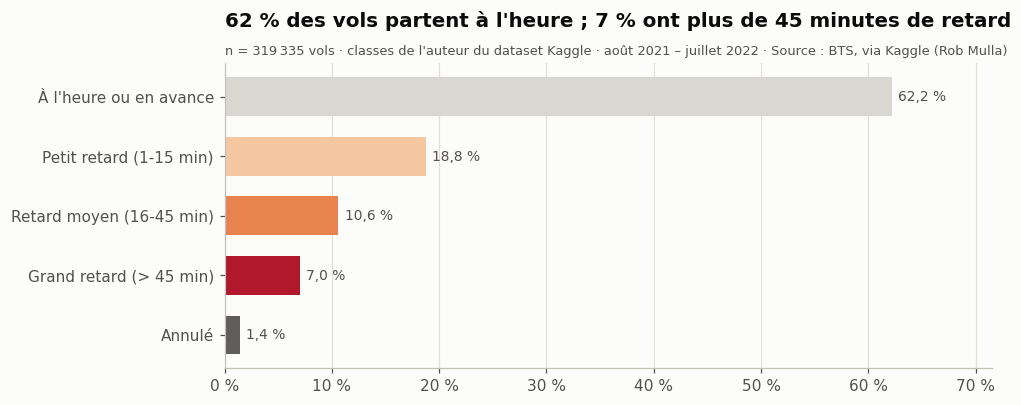

In [10]:
figures.f01_classes_retard(vols); plt.show()

> **Question.** Quelle est la gravité des retards au départ ?
>
> **Ce que l'on observe.** 62,2 % des vols partent à l'heure ou en avance, 18,8 % ont un petit retard, 7,0 % un grand retard (plus de 45 min) et 1,4 % sont annulés.
>
> **Interprétation.** Le retard « officiel » (15 min ou plus) ne concerne qu'une minorité de vols, mais les grands retards ne sont pas rares.
>
> **Limites.** Les bornes des classes (15, 45 min) sont des conventions ; d'autres bornes changeraient les pourcentages.
>
> **Lien avec la question principale.** Q1 : la gravité (et pas seulement la fréquence) servira à comparer les compagnies.

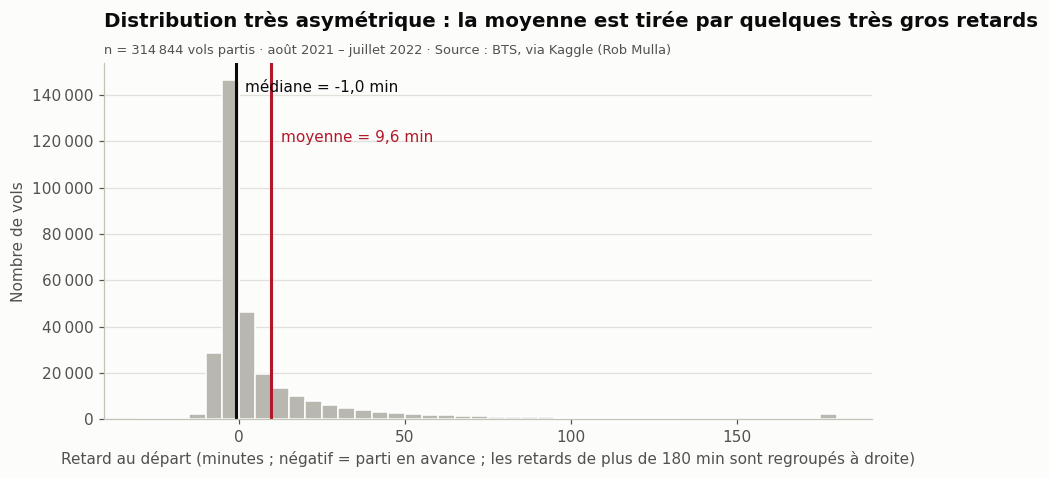

In [11]:
figures.f02_distribution_retard(vols); plt.show()

> **Question.** Quelle est la forme de la distribution du retard au départ ?
>
> **Ce que l'on observe.** La médiane vaut -1,0 min, la moyenne 9,6 min ; 90 % des vols ont moins de 33 min de retard, mais le 99e centile atteint 153 min. 13,2 % des vols sont atypiques selon la règle IQR.
>
> **Interprétation.** Distribution très asymétrique à droite : la moyenne est tirée par une minorité de très gros retards. Le vol « typique » est mieux décrit par la médiane ; on utilisera surtout des **pourcentages** et des **médianes**.
>
> **Limites.** Le graphique est coupé à 180 min (les retards plus grands sont regroupés à droite) pour rester lisible.
>
> **Lien avec la question principale.** Justifie le choix des indicateurs de toute la suite (% en retard plutôt que retard moyen).

### 4.1 Les valeurs extrêmes, une à une (classification du plan de travail)

La règle IQR **signale** des valeurs ; elle ne dit pas si elles sont fausses. On classe donc les plus extrêmes avec la grille
du plan : *erreur vérifiée* → corriger ou exclure ; *correction justifiable* → corriger ; *suspecte* → garder et signaler ;
*indéterminée* → isoler comme piste.

| Contrôle | Résultat |
|---|---|
| Retards de plus de 6 heures | 590 vols |
| Retards de plus de 24 heures | 5 vols (maximum : 2 650 min, soit 44 h) |
| Heure réelle − heure prévue ≠ retard annoncé | 5 vols sur environ 315 000 |
| Retard à l'arrivée incohérent avec le départ (écart > 5 h) | 0 vol |

**Décision :** valeurs suspectes : conservées et signalées (pas de preuve d'erreur ; un vol reporté au lendemain garde son numéro). Erreurs vérifiées : aucune.

## 5. Échantillonnage (partie 1) : les méthodes et la représentativité (Q5)

L'échantillonnage est présenté en deux temps. **Ici** (avant les analyses) : les 6 plans d'échantillonnage classiques,
les mesures, et ce que chaque méthode garde de la population (E1 distributions, E2 proportions, E5 temps).
**En section 9** (après les analyses) : la robustesse des **conclusions** de l'étude (E3, E4, E6, E7), car il faut d'abord
connaître les conclusions pour vérifier si un échantillon les retrouve.

### 5.1 Le principe de l'étude, en simple

Habituellement, on étudie un échantillon parce qu'on n'a **pas** la population entière. Ici, on a la population
(les 319 335 vols) : on peut donc **vérifier** ce que chaque méthode d'échantillonnage garde ou perd. La démarche :

1. **On connaît la vérité** : chaque statistique calculée sur les 319 335 vols (ex. 18,6 % de vols en retard).
2. **On tire un échantillon** de 5 000 vols avec une méthode.
3. **On mesure l'écart** entre l'échantillon et la vérité (les mesures sont expliquées en 5.3).
4. **On recommence 100 fois** (guide, étape 8 : « plusieurs échantillons plutôt qu'un seul »). Un seul tirage peut être
   chanceux ou malchanceux ; 100 tirages montrent l'erreur **habituelle** (la moyenne) et sa **variabilité** (la précision).
5. **On refait tout avec d'autres tailles** (1 000 à 20 000 vols) pour justifier la taille (E7).

**Ce qu'on compare n'est pas une seule variable** : chaque expérience (E1 à E7) a sa propre question et ses propres colonnes.
Une méthode n'est jamais félicitée pour ce qu'elle garantit **par construction** (ex. : la stratification par compagnie
respecte forcément la part de chaque compagnie — ce n'est pas un résultat, c'est la définition de la méthode).

**Naïf ou repondéré ?** *Naïf* : on calcule sur l'échantillon comme si c'était la population. *Repondéré* : chaque vol
compte avec un poids = (vols du groupe dans la population) / (vols du groupe dans l'échantillon). Indispensable pour les
méthodes qui déforment volontairement les proportions (le stratifié par compagnie, à part égale) quand on veut un chiffre **global**.

### 5.2 Les 6 méthodes : principe, application, intérêt, risque

**Aléatoire simple**
- **Principe** : Chaque vol a la même chance d'être choisi, comme un tirage au sort dans une urne.
- **Application à nos vols** : On tire 5 000 vols au hasard parmi les 319 335 (graine fixée pour pouvoir refaire le même tirage).
- **Utile pour** : C'est la méthode de référence : aucune hypothèse, aucun choix de groupes.
- **Risque** : Par hasard, elle peut oublier presque complètement les petites compagnies.
- **Ce qu'elle donne sur nos données** (moyenne de 100 tirages) : erreur de 0,42 point sur le % de retard global, en moyenne 4,2 compagnies sur 14 avec moins de 30 vols, 365 jours couverts sur 365, 63 % des conclusions conservées.

**Systématique**
- **Principe** : On range les vols dans l'ordre (date, heure), puis on prend un vol tous les k vols.
- **Application à nos vols** : k = 319 335 / 5 000 ≈ 64 : on prend un vol tous les 64, en partant d'un point tiré au hasard parmi les 64 premiers.
- **Utile pour** : L'échantillon est étalé régulièrement sur toute l'année.
- **Risque** : Si un cycle des données a la même longueur que le pas, on tombe toujours sur le même genre de vol (périodicité).
- **Ce qu'elle donne sur nos données** (moyenne de 100 tirages) : erreur de 0,45 point sur le % de retard global, en moyenne 4,3 compagnies sur 14 avec moins de 30 vols, 365 jours couverts sur 365, 65 % des conclusions conservées.

**Stratifié par compagnie**
- **Principe** : On découpe la population en groupes (les strates, ici les 14 compagnies) et on tire le MÊME NOMBRE de vols dans chacun (allocation à part égale).
- **Application à nos vols** : 5 000 / 14 ≈ 357 vols par compagnie, qu'elle soit grande ou petite.
- **Utile pour** : Notre question est de COMPARER les compagnies : chacune a assez de vols pour être jugée (même Mesa, 0,6 % des vols).
- **Risque** : L'échantillon ne ressemble plus à la population (Delta passe de 64 % à 7 %) : pour un chiffre global, il faut repondérer chaque vol (poids N_h / n_h).
- **Ce qu'elle donne sur nos données** (moyenne de 100 tirages) : erreur de 1,55 point sur le % de retard global, aucune compagnie avec moins de 30 vols, 365 jours couverts sur 365, 77 % des conclusions conservées. Repondérée : erreur de 1,07 point sur le % global. La repondération corrige le **biais** (le décalage systématique), mais pas la **précision** : les 64 % de vols Delta ne reposent plus que sur 357 vols tirés, d'où une erreur plus grande qu'avec un tirage aléatoire.

**Par grappes (jours)**
- **Principe** : On tire au hasard des journées entières (les grappes) et on garde tous leurs vols.
- **Application à nos vols** : Environ 6 jours tirés au hasard, avec tous leurs vols (environ 875 par jour).
- **Utile pour** : Dans la vraie vie, c'est la collecte la plus simple : observer quelques journées complètes.
- **Risque** : Les vols d'un même jour se ressemblent (même météo, mêmes incidents) : 6 jours ne représentent pas une année.
- **Ce qu'elle donne sur nos données** (moyenne de 100 tirages) : erreur de 3,55 points sur le % de retard global, en moyenne 4,2 compagnies sur 14 avec moins de 30 vols, 6 jours couverts sur 365, 60 % des conclusions conservées.

**Temporel (par jour)**
- **Principe** : Chaque jour est une strate : on tire le même pourcentage de vols dans chacun des 365 jours.
- **Application à nos vols** : 1,6 % des vols de chaque jour.
- **Utile pour** : Tous les jours de l'année sont représentés, dans les bonnes proportions : idéal pour suivre le temps.
- **Risque** : Ne protège pas les petites compagnies.
- **Ce qu'elle donne sur nos données** (moyenne de 100 tirages) : erreur de 0,42 point sur le % de retard global, en moyenne 4,3 compagnies sur 14 avec moins de 30 vols, 365 jours couverts sur 365, 63 % des conclusions conservées.

**Répété (bootstrap)**
- **Principe** : Tirage au hasard où un vol déjà tiré est « remis dans l'urne » : il peut être tiré plusieurs fois. On répète le tirage pour voir comment un résultat varie.
- **Application à nos vols** : 5 000 tirages avec remise : quelques vols apparaissent deux fois.
- **Utile pour** : Ce n'est pas un plan d'enquête : c'est l'outil qui sert à mesurer la variabilité d'un résultat en répétant les tirages.
- **Risque** : Contient des doublons ; ne dit rien de plus que l'aléatoire simple sur la représentativité.
- **Ce qu'elle donne sur nos données** (moyenne de 100 tirages) : erreur de 0,48 point sur le % de retard global, en moyenne 4,2 compagnies sur 14 avec moins de 30 vols, 365 jours couverts sur 365, 65 % des conclusions conservées.

### 5.3 Les mesures : comment on juge un échantillon

| Mesure | Ce qu'elle mesure | Calcul | Comment la lire |
|---|---|---|---|
| **Erreur absolue** | L'écart entre la valeur dans l'échantillon et la vraie valeur (population). | Δ = |T(S) − T(P)| (guide, étape 8). Exemple : 18,6 % dans la population, 19,1 % dans l'échantillon → 0,5 point. | Plus petit = meilleur. Exprimée dans l'unité de la statistique (points de %, minutes...). |
| **Distance de Kolmogorov-Smirnov (KS)** | Si la FORME d'une distribution est conservée, pas seulement sa moyenne. | On trace pour chaque valeur x la proportion de vols dont le retard est ≤ x (courbe cumulée), dans la population et dans l'échantillon ; KS = le plus grand écart vertical entre les deux courbes. | 0 = formes identiques ; 0,05 = à un endroit, 5 % des vols sont « mal placés ». |
| **Erreurs sur les centiles (P50, P90, P99)** | Si le centre (médiane), la queue (P90) et les extrêmes (P99) sont conservés. | Erreur absolue sur chaque centile, en minutes. | Plus petit = meilleur ; P99 est naturellement instable. |
| **Plus grand écart de part** | Si les proportions (parts des compagnies, des classes de retard) sont respectées. | Pour chaque catégorie : |part dans l'échantillon − part dans la population| ; on garde le plus grand. | En points de % ; 0 = proportions parfaites. |
| **Compagnies avec moins de 30 vols** | Si des petits groupes sont « perdus ». | Nombre de compagnies (sur 14) qui ont moins de 30 vols dans l'échantillon. En dessous de 30 vols, la marge d'erreur d'un pourcentage dépasse ± 18 points (1,96 × √(0,25 / 30)) : on ne peut plus la juger. | 0 = aucune compagnie perdue. |
| **Écart moyen sur une courbe** | Si un profil (retard par heure, par mois) est conservé. | Moyenne des écarts absolus point par point entre la courbe de l'échantillon et celle de la population. | En points de % ; plus petit = meilleur. |
| **Corrélation de rang (Spearman) du classement** | Si l'ordre des compagnies est conservé. | Corrélation entre le classement des compagnies dans l'échantillon et dans la population (1 = même ordre). Toujours la lire avec le nombre de compagnies comparables : classer 3 compagnies est plus facile que 14. | Plus proche de 1 = meilleur. |
| **% de tirages où une conclusion reste vraie** | Si l'échantillon permet d'arriver à la même conclusion que la population. | Sur 100 tirages, combien de fois la conclusion (ex. « Southwest plus en retard que Delta ») est encore vraie. | 100 % = conclusion robuste ; moins de 50 % = l'échantillon ne permet pas de conclure. |

In [12]:
from sampling_study import CONCLUSIONS, DESCRIPTION_MESURES, DOSSIER_ECHANTILLONNAGE, synthese
mesures = pd.read_parquet(DOSSIER_ECHANTILLONNAGE / "mesures_methodes.parquet")
mesures_tailles = pd.read_parquet(DOSSIER_ECHANTILLONNAGE / "mesures_tailles.parquet")
resume = synthese(mesures).droplevel("taille")   # moyenne des 100 tirages, par méthode et estimateur
resume.index = [f"{m} (repondéré)" if e == "repondéré" else m for m, e in resume.index]
print(len(mesures), "échantillons de 5 000 vols mesurés")
pd.DataFrame(DESCRIPTION_MESURES, index=["expérience", "description", "unité"]).T

700 échantillons de 5 000 vols mesurés


,expérience,description,unité
E1_ks_retard,E1,Distance KS sur la distribution du retard,0 à 1
E1_ks_roulage,E1,Distance KS sur la distribution du roulage,0 à 1
E1_ks_rattrapage,E1,Distance KS sur la distribution du rattrapage,0 à 1
E1_erreur_p50_retard,E1,Erreur sur le centile 50 du retard,min
E1_erreur_p90_retard,E1,Erreur sur le centile 90 du retard,min
E1_erreur_p99_retard,E1,Erreur sur le centile 99 du retard,min
E1_erreur_p50_roulage,E1,Erreur sur le centile 50 du roulage,min
E1_erreur_p90_roulage,E1,Erreur sur le centile 90 du roulage,min
E1_erreur_p99_roulage,E1,Erreur sur le centile 99 du roulage,min
E1_erreur_p50_rattrapage,E1,Erreur sur le centile 50 du rattrapage,min


### 5.4 E1 — La forme des distributions est-elle conservée ?

**Question** : le retard au départ, le roulage et le temps rattrapé en vol ont-ils la même distribution dans l'échantillon ?
**Colonnes** : `DepDelayMinutes`, `TaxiOut`, `minutes_rattrapees`. **Mesures** : distance KS, erreurs sur P50, P90, P99.

In [13]:
resume[['E1_ks_retard', 'E1_erreur_p50_retard', 'E1_erreur_p90_retard', 'E1_erreur_p99_retard', 'E1_ks_roulage']].round(3).sort_values('E1_ks_retard')

,E1_ks_retard,E1_erreur_p50_retard,E1_erreur_p90_retard,E1_erreur_p99_retard,E1_ks_roulage
Aléatoire simple,0.009,0.00,1.02,8.49,0.010
Répété (bootstrap),0.009,0.00,1.15,7.83,0.010
Systématique,0.009,0.00,1.18,7.37,0.010
Temporel (par jour),0.009,0.00,1.18,7.66,0.010
Stratifié par compagnie (repondéré),0.023,0.00,2.88,20.92,0.025
Stratifié par compagnie,0.025,0.00,8.80,72.76,0.145
Par grappes (jours),0.046,0.02,8.66,25.33,0.041


> **Réponse.** La forme est très bien conservée par les méthodes qui tirent des vols un par un : distance KS de
> 0,009 pour « Aléatoire simple », contre 0,046 pour « Par grappes (jours) ». Les centiles extrêmes (P99) sont les plus difficiles à retrouver,
> car ils reposent sur 1 % des vols (environ 50 vols dans un échantillon de 5 000).
> **À retenir** : pour décrire la forme d'une variable, n'importe quel tirage vol par vol suffit ; les grappes de jours non.

### 5.5 E2 — Les proportions sont-elles respectées ? Perd-on des petits groupes ?

**Question** : l'échantillon garde-t-il la part de chaque compagnie et de chaque classe de retard ? Les petites compagnies
ont-elles encore assez de vols pour être étudiées ? **Colonnes** : `compagnie`, `classe_retard`, `DepDelayMinutes > 45`.

In [14]:
resume[['E2_nb_compagnies_moins_30_vols', 'E2_ecart_max_parts_compagnies', 'E2_ecart_max_classes_retard', 'E2_erreur_pct_grand_retard']].round(3).sort_values('E2_nb_compagnies_moins_30_vols')

,E2_nb_compagnies_moins_30_vols,E2_ecart_max_parts_compagnies,E2_ecart_max_classes_retard,E2_erreur_pct_grand_retard
Stratifié par compagnie,0.00,57.161,2.583,2.244
Stratifié par compagnie (repondéré),0.00,0.000,1.819,0.799
Aléatoire simple,4.19,0.660,0.728,0.263
Par grappes (jours),4.22,0.920,4.527,1.971
Répété (bootstrap),4.23,0.723,0.732,0.271
Temporel (par jour),4.30,0.747,0.752,0.307
Systématique,4.35,0.720,0.742,0.314


> **Réponse.** Avec un tirage aléatoire simple, en moyenne 4,2
> compagnies sur 14 ont moins de 30 vols : on ne peut pas les juger. Le stratifié par compagnie n'en perd aucune
> (357 vols par compagnie), mais il déforme les parts des compagnies
> (plus grand écart : 57,2 points en naïf — c'est
> voulu, et la repondération le corrige : 0,0 point).
> **À retenir** : « représentatif » (bonnes proportions) et « utile pour comparer les groupes » (assez de vols par groupe)
> sont deux objectifs différents, que la même méthode ne peut pas remplir sans repondération.

### 5.6 E5 — Le temps est-il préservé ?

**Question** : la série mensuelle du % de retard est-elle retrouvée ? Combien de jours de l'année sont couverts ?
**Colonnes** : `annee_mois`, `FlightDate`, `DepDel15`.

In [15]:
resume[['E5_ecart_moyen_serie_mensuelle', 'E5_nb_jours_couverts']].round(3).sort_values('E5_ecart_moyen_serie_mensuelle')

,E5_ecart_moyen_serie_mensuelle,E5_nb_jours_couverts
Temporel (par jour),1.424,365.0
Aléatoire simple,1.475,365.0
Répété (bootstrap),1.508,365.0
Systématique,1.544,365.0
Stratifié par compagnie,2.466,365.0
Stratifié par compagnie (repondéré),3.667,365.0
Par grappes (jours),6.308,6.0


> **Réponse.** « Temporel (par jour) » retrouve la série mensuelle à 1,4 point près en moyenne ; « Par grappes (jours) » s'en écarte de 6,3 points,
> car 6 jours seulement sont tirés : la plupart des mois ne sont
> pas observés du tout. **À retenir** : dès que la question porte sur le temps, il faut que l'échantillon couvre toute la période
> (temporel par jour, systématique) ; les grappes de jours sont inadaptées.

### 5.7 Le chiffre global : quelle précision selon la méthode ?

Erreur sur le % de vols en retard, pour chacun des 100 tirages de chaque méthode (un point = un tirage).

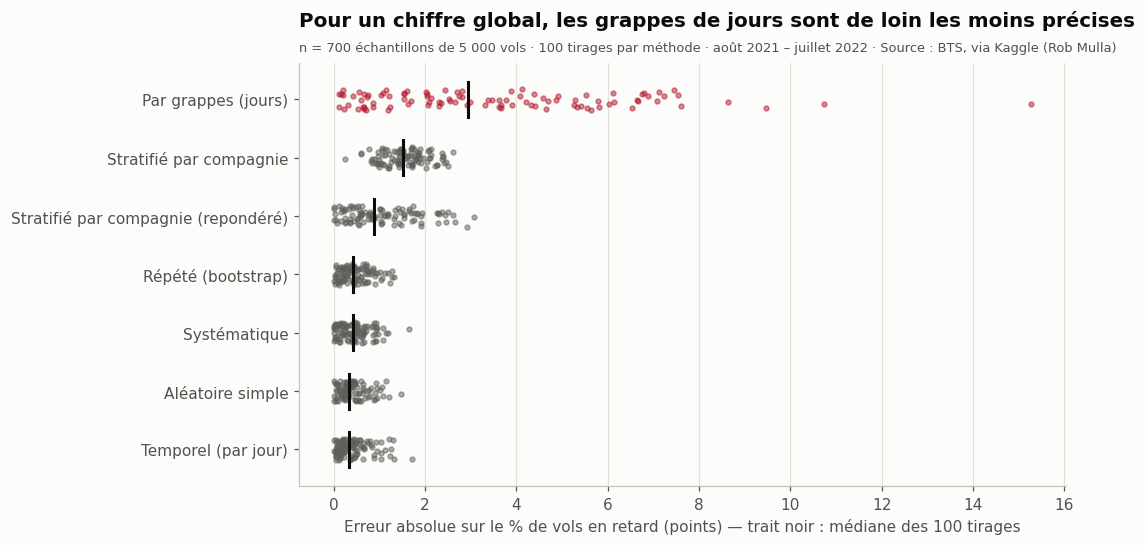

In [16]:
figures.s1_erreur_pourcentage_global(mesures); plt.show()

> **Réponse.** Erreur habituelle (moyenne de 100 tirages) : 0,42 point avec un tirage
> aléatoire simple, 3,55 points avec les grappes de jours, dont les tirages s'étalent
> beaucoup plus. **À retenir** : pour un chiffre global, les méthodes qui tirent les vols un par un suffisent ; tirer des
> jours entiers rend le résultat dépendant des jours tombés au hasard.

### 5.8 La taille de l'échantillon : pourquoi n = 5 000 ?

On veut estimer le % de vols en retard (p) à **± e près**, avec **95 % de confiance**. Pour un tirage aléatoire simple :

$$n_0 = \frac{z^2 \, p\,(1-p)}{e^2} \qquad\qquad n = \frac{n_0}{1 + \dfrac{n_0 - 1}{N}}$$

| Paramètre | Signification | Valeur |
|---|---|---|
| N | taille de la population | 319 335 vols |
| p | proportion à estimer (% de vols en retard) | 0,186 (0,5 si inconnue : cas le plus prudent) |
| z | valeur du niveau de confiance | 1,96 (95 %) |
| e | marge d'erreur acceptée | 0,01 (± 1 point) |
| n / N | fraction de sondage | 1,57 % pour n = 5 000 |

**Résultat :** pour ± 1 point, **n ≈ 5 703 vols** (≈ 9 324 si p est inconnu ;
≈ 1 445 pour ± 2 points). La formule inverse donne la marge de n = 5 000 :
$e = z\sqrt{p(1-p)/n}\sqrt{(N-n)/(N-1)}$ = **± 1,07 point**. 5 000 vols atteignent donc
presque la précision visée de ± 1 point, pour 1,6 % de la population.

**Le nombre de colonnes n'intervient pas** : on tire des lignes, et chaque vol tiré apporte toutes ses colonnes. Seul
compte l'indicateur estimé (son p et sa marge e).

**Comparer les compagnies demande un n par compagnie.** Même formule dans la strate la plus petite (Mesa,
N_h = 1 759, p_h = 0,129, e = ± 5 points) : n_h ≈ 157 vols.
Un tirage aléatoire de 5 000 vols n'en donne qu'environ 28 : c'est pourquoi on stratifie
pour comparer les compagnies. La section 9.5 (E7) vérifie ces tailles par simulation.

In [17]:
from sampling import marge_erreur, taille_echantillon
N, p = len(vols), vols.loc[~vols["Cancelled"], "DepDel15"].mean()
print(f"n pour ± 1 point : {taille_echantillon(N, p, 0.01):.0f} vols")
print(f"marge de n = 5 000 : ± {100 * marge_erreur(5000, N, p):.2f} point")

n pour ± 1 point : 5703 vols
marge de n = 5 000 : ± 1.07 point


## 6. Analyse univariée : décrire chaque variable

Une variable à la fois. Les variables numériques ont été décrites en section 4 ; ici, les variables
**catégorielles** (effectifs, pourcentages, diagramme en barres).

In [18]:
frequences(vols, 'type_compagnie')

,effectif,pourcentage
type_compagnie,,
Majeure,217402,68.1
Régionale,52933,16.6
Bas coût,49000,15.3


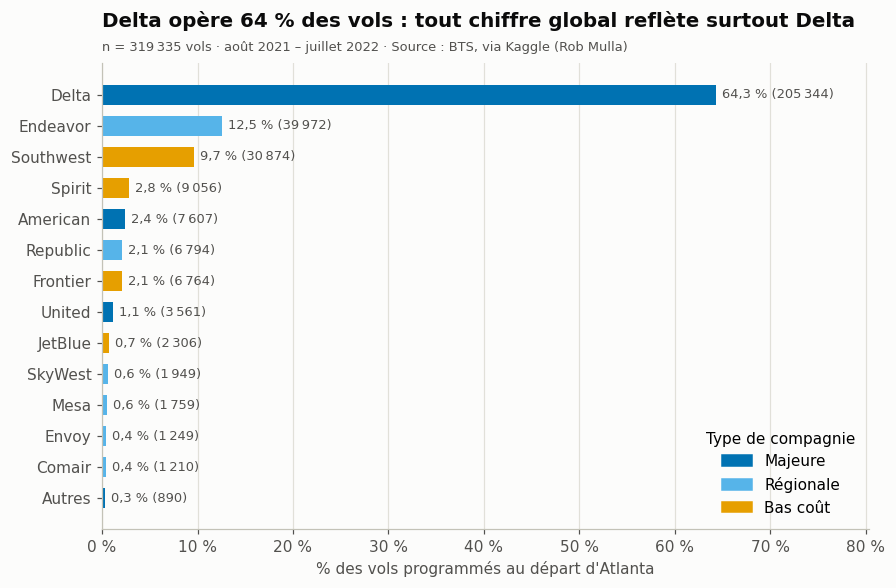

In [19]:
figures.f15_vols_par_compagnie(vols); plt.show()

> **Question.** Comment les vols se répartissent-ils entre les compagnies ?
>
> **Ce que l'on observe.** 14 compagnies, très inégales : Delta opère 64,3 % des vols, les plus petites moins de 1 %. Par type : majeures 68,1 %, régionales 16,6 %, bas coût 15,3 %.
>
> **Interprétation.** Population très déséquilibrée : un chiffre « global » décrit surtout Delta. Pour comparer les compagnies, il faut les regarder une par une, et un échantillon devra protéger les petites (voir l'échantillonnage).
>
> **Limites.** La classification des types est en partie notre choix (« bas coût »), documentée au nettoyage.
>
> **Lien avec la question principale.** Q1 et Q5 : justifie la comparaison compagnie par compagnie et la stratification.

## 7. Analyse bivariée : relier deux variables

Deux variables à la fois, avec le graphique adapté à leurs types (cahier des charges, §11) : temps × mesure → ligne ;
catégorie × mesure → barres ; numérique × numérique → nuage de points puis corrélation.

### 7.1 Le retard selon le jour, la saison et l'heure (temps × retard)

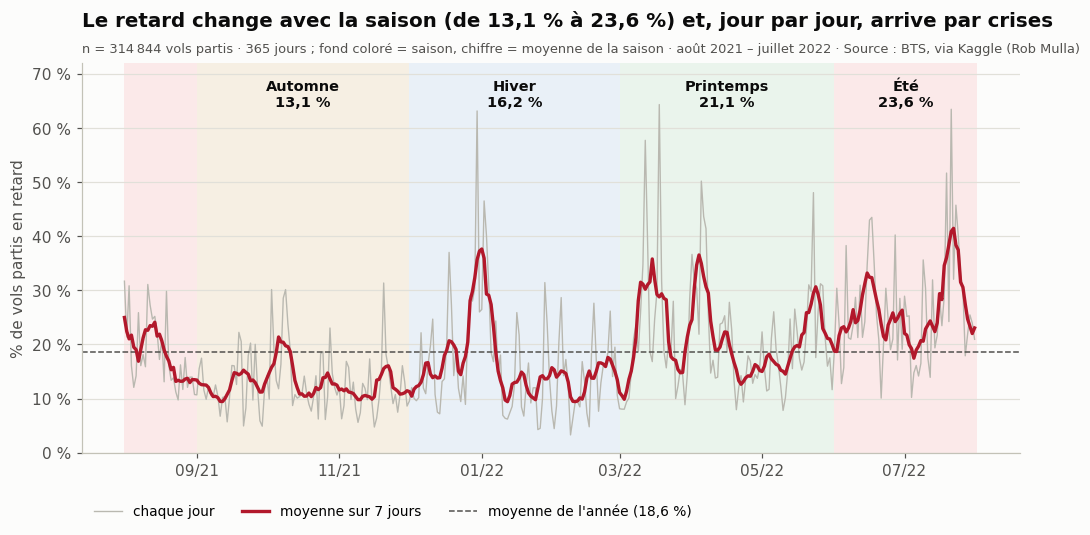

In [20]:
figures.f03_retard_par_jour_saisons(vols); plt.show()

> **Question.** Le retard varie-t-il au cours de l'année ?
>
> **Ce que l'on observe.** Par saison : de 13,1 % (automne) à 23,6 % (été). Jour par jour : des pics de quelques jours dans chaque saison.
>
> **Interprétation.** Forte variation saisonnière (l'été, étudié seul dans la version 1, est la saison la plus difficile), et le retard arrive par crises courtes (section 7.1 b).
>
> **Limites.** Une seule année : chaque mois n'est observé qu'une fois, on ne peut pas séparer « saison » et « événements de cette année-là ».
>
> **Lien avec la question principale.** Q3 : comparer les compagnies sur l'année entière évite de juger sur une seule saison.

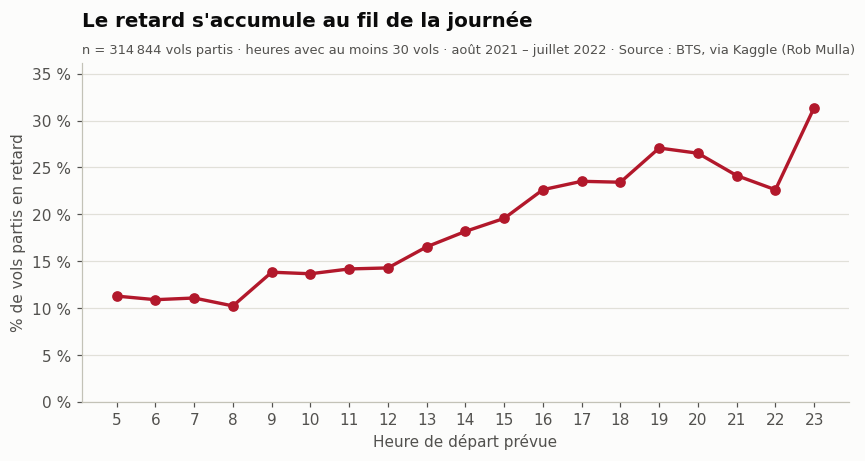

In [21]:
figures.f04_retard_par_heure(vols); plt.show()

> **Question.** Le retard dépend-il de l'heure de départ ?
>
> **Ce que l'on observe.** Le % de vols en retard augmente régulièrement du matin au soir.
>
> **Interprétation.** Hypothèse cohérente avec H4 : les retards de la journée s'accumulent.
>
> **Limites.** Association, pas causalité ; les heures très tôt et très tard ont moins de vols.
>
> **Lien avec la question principale.** Prépare Q2 (l'heure, variable de composition) et Q4 (effet domino).

**Les trois cas de l'analyse bivariée** (deux variables à la fois, pour chercher le **lien** entre elles) :

| Les deux variables | Exemple | Graphique | Mesure de la force du lien |
|---|---|---|---|
| catégorielle × catégorielle | type de compagnie × classe de retard | barres empilées à 100 % | V de Cramér (0 à 1) |
| catégorielle × numérique | compagnie × minutes de retard | médiane, quartile, 90e centile par groupe | ε² de Kruskal-Wallis |
| numérique × numérique | retard au départ × retard à l'arrivée | nuage de points | ρ de Spearman, r de Pearson |

**Attention :** avec plus de 300 000 vols, presque tout lien est « significatif » (p < 0,001). Ce qui compte, c'est la
**force** du lien, pas la p-valeur.

### 7.1 b — Jour par jour : ce que la moyenne du mois cachait

La courbe par mois montre la saison. Mais une moyenne sur 30 jours **efface les crises courtes**. On refait donc la courbe
**jour par jour** (365 points), avec une moyenne mobile sur 7 jours pour voir la tendance.

In [22]:
from approfondissement import resume_journalier, serie_journaliere
from contexte import verifier_evenements
serie_journaliere(vols).describe().round(1)

,nb_vols,pct_retard,pct_annules,moyenne_7_jours
count,365.0,365.0,365.0,365.0
mean,874.9,18.5,1.4,18.5
std,67.4,10.2,2.8,7.1
min,638.0,3.3,0.0,9.4
25%,834.0,10.9,0.1,13.2
50%,885.0,16.1,0.6,16.3
75%,931.0,23.7,1.5,22.6
max,967.0,64.3,33.2,41.5


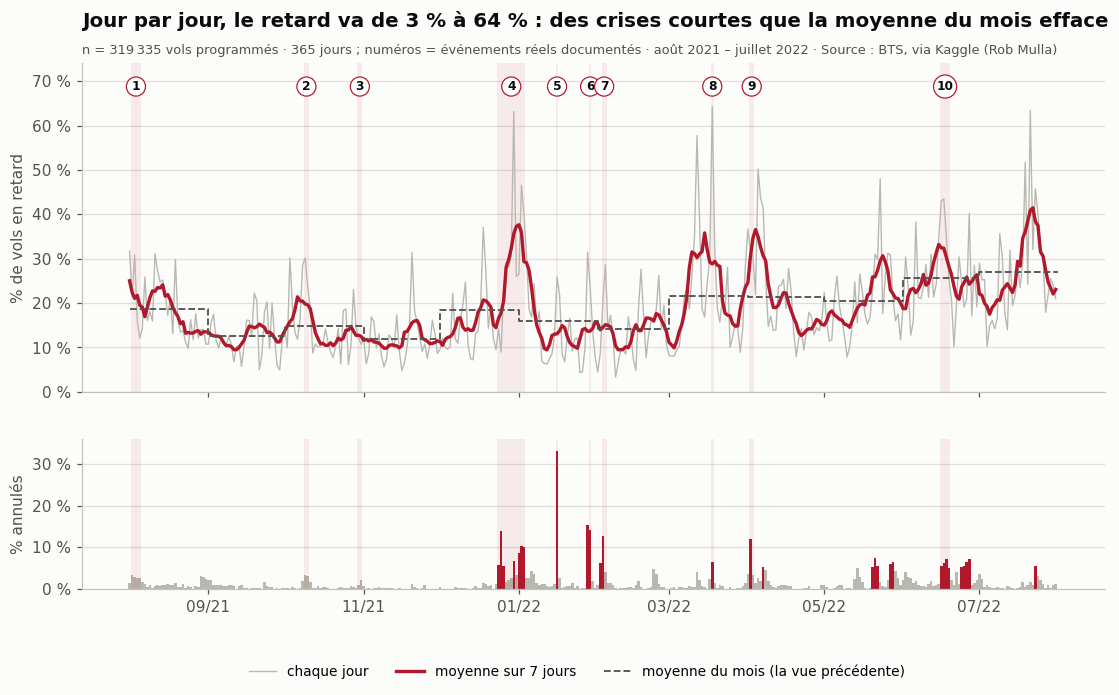

In [23]:
figures.f16_retard_par_jour(vols); plt.show()

> **Question.** Que montre la vue jour par jour que la vue par mois ne montrait pas ?
>
> **Ce que l'on observe.** Le retard va de 3,3 % (2022-02-08) à 64,3 % (2022-03-18) ; l'écart-type des jours (10,2 points) est le double de celui des mois (4,9). 16 jours dépassent 40 % de retard, et les 10 % pires jours concentrent 21,5 % de tous les retards de l'année. Le 2022-01-16, 33,2 % des vols sont annulés.
>
> **Interprétation.** Le retard arrive par **épisodes** : un mauvais jour est souvent suivi d'un autre (corrélation d'un jour au lendemain : 0,59). Les 10 épisodes numérotés correspondent à des événements réels documentés (tableau ci-dessous). C'est aussi pourquoi les **grappes de jours** échouent (section 5) : tirer 6 jours au hasard, c'est risquer de tomber sur une crise.
>
> **Limites.** Les causes viennent de sources extérieures (presse, compagnies), pas de notre fichier. Deux jours très anormaux (2022-03-12, 2022-07-21) n'avaient pas de source de presse ; la fusion avec la météo (section 10 du document principal) les explique : rafales à 77 km/h le 12 mars, 11 heures de pluie le 21 juillet.
>
> **Lien avec la question principale.** Q3 et Q4 : la variation dans le temps est surtout faite de crises ; Q5 : explique l'échec des grappes.

**Les événements réels, vérifiés dans nos données** (« normal » = la moyenne de ces compagnies sur toute l'année) :

| N° | Dates | Événement | Compagnies | Annulés (normal) | En retard (normal) | Ce qui s'est passé | Source |
|---|---|---|---|---|---|---|---|
| 1 | 2021-08-02 → 2021-08-05 | Crise opérationnelle de Spirit | Spirit | 79,1 % (2,5 %) | 65,2 % (24,3 %) | Météo, manque de personnel et équipages arrivés à leur limite d'heures de vol : Spirit annule plus de 2 800 vols du 30 juillet au 9 août 2021 (coût : 50 millions de dollars). | [lien](https://www.cbsnews.com/amp/news/long-lines-stranded-passengers-and-more-than-half-of-scheduled-flights-cancelled-as-spirit-airlines-enters-fifth-day-of-operational-issues) |
| 2 | 2021-10-09 → 2021-10-10 | Week-end noir de Southwest | Southwest | 26,5 % (1,8 %) | 59,0 % (29,8 %) | Problèmes de contrôle aérien en Floride et météo : Southwest annule 29 % de son programme le dimanche. Les rumeurs de grève des pilotes ont été démenties. | [lien](https://abc13.com/post/southwest-cancellations-airlines-flights-delays/11107033/) |
| 3 | 2021-10-30 → 2021-10-31 | Halloween d'American | American | 31,7 % (2,3 %) | 17,9 % (17,4 %) | Vents violents à Dallas-Fort Worth, son plus grand hub (2 pistes sur 5 utilisables), aggravés par le manque de personnel : plus de 1 700 vols annulés en un week-end. | [lien](https://www.wabe.org/american-airlines-has-cancelled-nearly-1-600-flights-since-friday/) |
| 4 | 2021-12-24 → 2022-01-03 | Noël 2021 : variant Omicron | toutes | 6,2 % (1,3 %) | 31,7 % (18,2 %) | Pilotes et équipages en quarantaine (Omicron), plus la météo : Delta annule 344 de ses 3 000 vols le soir de Noël ; les annulations continuent jusqu'au début janvier. | [lien](https://www.mprnews.org/story/2021/12/24/delta-cancels-christmas-eve-flights-due-to-crew-shortages) |
| 5 | 2022-01-16 → 2022-01-16 | Tempête d'hiver Izzy | toutes | 33,2 % (1,3 %) | 25,9 % (18,5 %) | Neige et verglas sur le Sud-Est : Delta supprime environ 300 vols de son hub d'Atlanta, 110 000 foyers sans électricité en Géorgie. | [lien](https://news.yahoo.com/winter-storm-izzy-worst-ice-205615918.html) |
| 6 | 2022-01-29 → 2022-01-29 | Blizzard du Nord-Est | JetBlue | 83,3 % (3,5 %) | 100,0 % (34,4 %) | Blizzard sur New York (JFK) et Boston, les bases de JetBlue : 68 % de son programme annulé ce jour-là. | [lien](https://foxbusiness.com/lifestyle/thousands-flights-delayed-canceled-winter-storm) |
| 7 | 2022-02-03 → 2022-02-04 | Tempête d'hiver au Texas | American, Southwest | 18,6 % (1,9 %) | 32,0 % (27,5 %) | Pluie verglaçante à Dallas : American annule environ 700 vols (23 % de son programme) ; Southwest suspend ses vols à Dallas Love Field. | [lien](https://thepointsguy.com/news/winter-weather-cancelations-feb-3) |
| 8 | 2022-03-18 → 2022-03-18 | Orages sur Atlanta | toutes | 6,5 % (1,4 %) | 64,3 % (18,4 %) | Orages sur l'agglomération : la FAA retient les avions aux portes et au roulage (31 à 45 min). | [lien](https://www.atlantanewsfirst.com/2022/03/18/delays-reported-hartsfield-jackson-atlanta-international-airport-because-thunderstorm) |
| 9 | 2022-04-02 → 2022-04-03 | Orages en Floride | JetBlue, Spirit, Frontier, Southwest | 21,7 % (2,2 %) | 69,2 % (28,8 %) | Orages en Floride et programmes de régulation du contrôle aérien, en pleine période de vacances : plus de 3 300 vols annulés aux États-Unis ; JetBlue et Spirit annulent un tiers de leurs vols. | [lien](https://www.wlrn.org/local-news/2022-04-04/airlines-cancel-more-than-3-500-us-flights-over-weekend) |
| 10 | 2022-06-16 → 2022-06-19 | Week-end de Juneteenth | toutes | 5,9 % (1,4 %) | 36,8 % (18,4 %) | Week-end de fête (Juneteenth, fête des pères), trafic record, météo, contrôle aérien et absences : plus de 5 000 vols annulés aux États-Unis ; près de 100 à Atlanta le dimanche. | [lien](https://www.nbcnews.com/news/holiday-weekend-sees-massive-amount-flight-cancellations-rcna34297) |

*Prudence :* le blizzard du 29 janvier ne concerne que 6 vols JetBlue au départ d'Atlanta ce jour-là ; le pourcentage est donc fragile, même si l'événement est bien documenté.

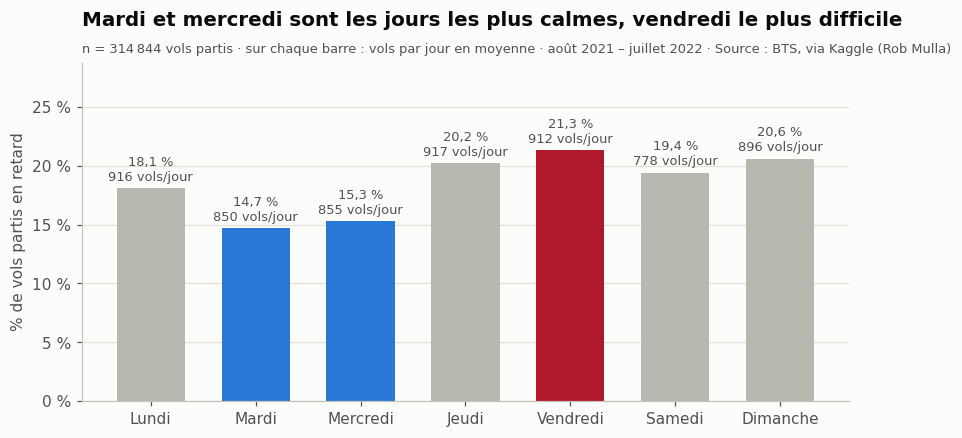

In [24]:
figures.f17_jour_semaine(vols); plt.show()

> **Question.** Le jour de la semaine compte-t-il ?
>
> **Ce que l'on observe.** Mardi (14,7 %) et mercredi (15,3 %) sont les jours les plus calmes, vendredi (21,3 %) le plus difficile. Mardi ou mercredi est le meilleur jour **à chaque saison**. V de Cramér = 0,062.
>
> **Interprétation.** Les jours calmes sont aussi ceux où il y a le moins de vols (environ 850 par jour contre 916 le lundi et le jeudi) : moins de trafic, moins d'attente. Mais le samedi, le jour le plus creux (778 vols), n'est pas calme : le nombre de vols n'explique pas tout (les départs en week-end et les vacances jouent aussi, hypothèse).
>
> **Limites.** Lien **faible** (V = 0,06) : le jour de la semaine compte moins que l'heure ou la compagnie.
>
> **Lien avec la question principale.** Q2 : le jour de la semaine est une variable de composition possible, plus faible que l'heure.

### 7.2 Compagnie × retard : comparer les compagnies (Q1)

In [25]:
profil_compagnies(vols)

,type,nb_vols,part_vols_pct,pct_retard,pct_retard_ou_annule,pct_annules,pct_grand_retard,retard_p90_min,roulage_median_min,rattrapage_median_min,distance_mediane,nb_destinations,part_vols_soir_pct,marge_95_pct_retard
compagnie,,,,,,,,,,,,,,
Endeavor (Delta Connection),Régionale,39972,12.5,9.7,10.2,0.5,4.3,14.0,15.0,5.0,350.0,69,29.7,0.3
Mesa,Régionale,1759,0.6,12.9,15.3,2.8,7.8,27.0,15.0,12.0,689.0,4,9.4,1.6
Republic,Régionale,6794,2.1,14.3,16.7,2.9,7.8,31.0,16.0,6.0,606.0,15,22.3,0.8
Delta,Majeure,205344,64.3,18.1,19.1,1.2,6.4,31.0,14.0,6.0,577.0,133,33.0,0.2
American,Majeure,7607,2.4,17.4,19.5,2.5,8.4,38.0,16.0,11.0,666.0,9,15.2,0.9
Envoy,Régionale,1249,0.4,18.0,19.5,1.8,7.7,34.5,15.0,11.0,594.0,5,21.3,2.2
Comair,Régionale,1210,0.4,18.0,19.6,2.0,8.2,32.5,18.0,9.0,226.0,3,27.5,2.2
United,Majeure,3561,1.1,17.4,19.9,3.0,8.6,38.8,16.0,6.0,746.0,6,14.4,1.3
Autres,Majeure,890,0.3,18.8,20.9,2.6,5.8,27.4,17.0,4.0,2182.0,1,23.1,2.6


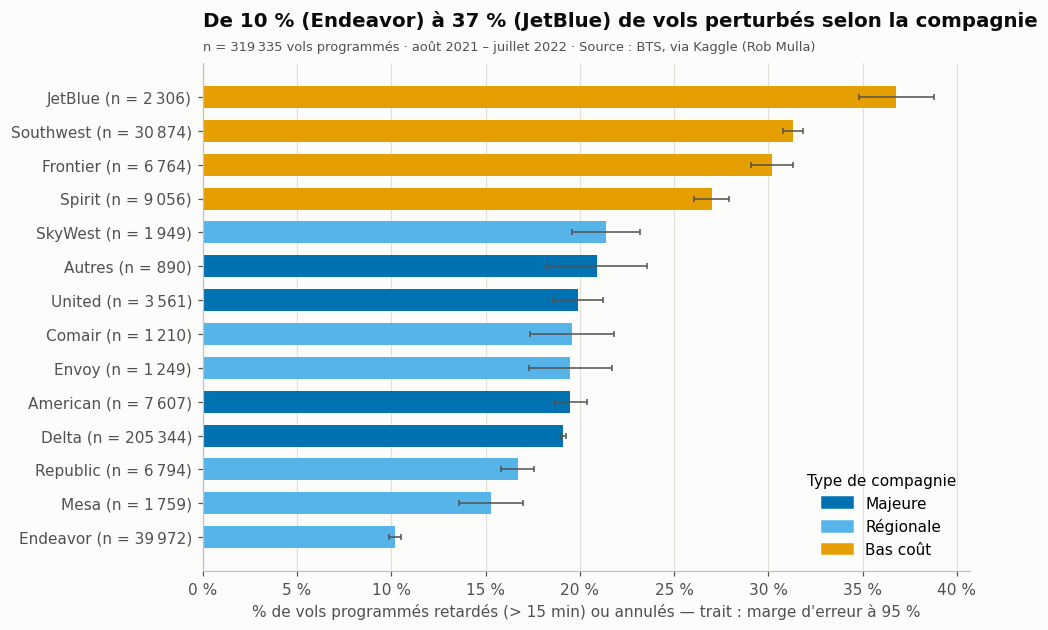

In [26]:
figures.f06_compagnies_retard_ou_annule(vols); plt.show()

> **Question.** Les compagnies diffèrent-elles en ponctualité ?
>
> **Ce que l'on observe.** De 10,2 % (Endeavor) à 36,8 % (JetBlue) de vols retardés ou annulés. En moyenne : compagnies régionales 12,1 %, majeures 19,1 %, à bas coût 30,6 %.
>
> **Interprétation.** Les écarts sont bien plus grands que les marges d'erreur (traits) : H1 est confirmée pour les grandes différences. Pour les compagnies proches (American, United, Envoy, Comair, Delta…), les marges se chevauchent : on ne peut pas les départager.
>
> **Limites.** Delta représente 64,3 % des vols : tout chiffre « global » reflète surtout Delta.
>
> **Lien avec la question principale.** Réponse directe à Q1 (fréquence des perturbations).

**Catégorielle × catégorielle : la gravité selon le type de compagnie.**

In [27]:
from approfondissement import classes_par_type
classes_par_type(vols)

classe_retard,À l'heure ou en avance,Petit retard (1-15 min),Retard moyen (16-45 min),Grand retard (> 45 min),Annulé
type_compagnie,,,,,
Bas coût,45.8,24.6,16.2,11.0,2.3
Majeure,61.7,19.9,10.6,6.5,1.3
Régionale,79.3,9.0,5.4,5.3,1.0


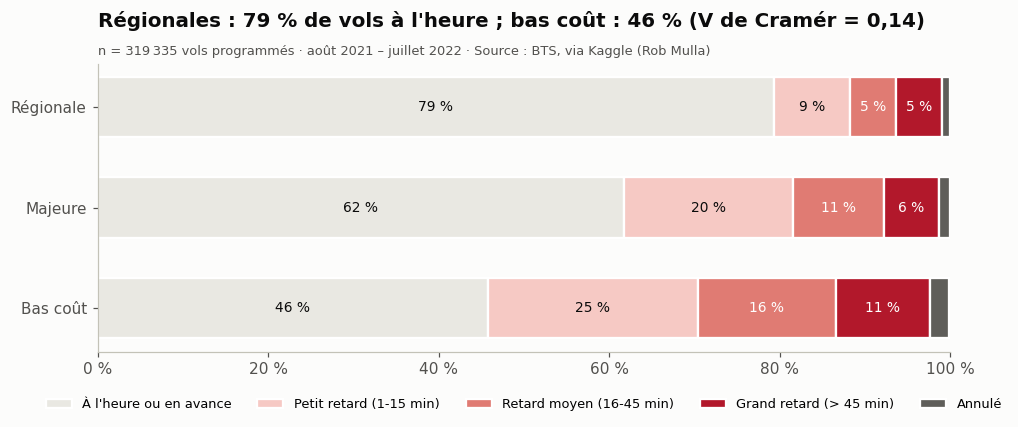

In [28]:
figures.f19_classes_par_type(vols); plt.show()

> **Question.** Le type de compagnie est-il lié à la gravité du retard ?
>
> **Ce que l'on observe.** À l'heure : 79,3 % des vols régionaux, 61,7 % des majeurs, 45,8 % des vols à bas coût ; les grands retards sont deux fois plus fréquents chez les bas coût. V de Cramér (type × retardé ou annulé) = 0,133.
>
> **Interprétation.** Les types diffèrent sur **toute** l'échelle de gravité, pas seulement sur le seuil de 15 minutes.
>
> **Limites.** Lien modéré-faible : le type ne dit pas tout (voir la variation à l'intérieur des types).
>
> **Lien avec la question principale.** Q1 : fréquence ET gravité.

**Catégorielle × numérique : les minutes de retard selon la compagnie.**

In [29]:
from approfondissement import quantiles_retard_par_compagnie
quantiles_retard_par_compagnie(vols)

,mediane,q3,p90,type
compagnie,,,,
Endeavor (Delta Connection),0.0,0.0,14.0,Régionale
Mesa,0.0,0.0,27.0,Régionale
Autres,0.0,10.0,27.4,Majeure
Delta,0.0,7.0,31.0,Majeure
Republic,0.0,0.0,31.0,Régionale
Comair,0.0,5.0,32.5,Régionale
Envoy,0.0,6.0,34.5,Régionale
American,0.0,4.0,38.0,Majeure
United,0.0,5.0,38.8,Majeure


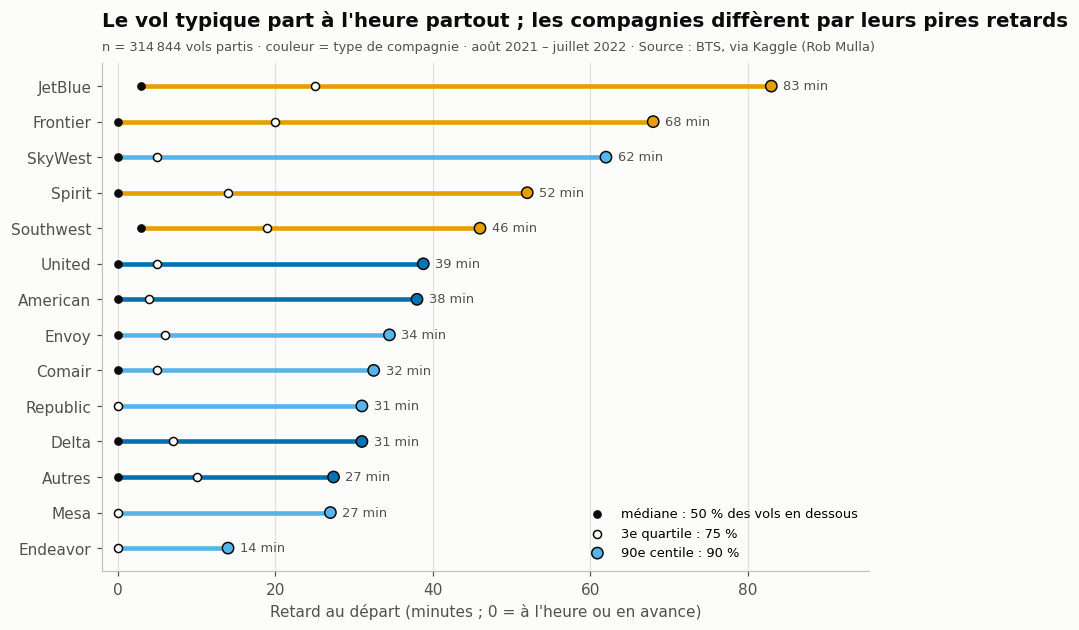

In [30]:
figures.f18_queue_retard_compagnies(vols); plt.show()

> **Question.** Comment les minutes de retard se répartissent-elles dans chaque compagnie ?
>
> **Ce que l'on observe.** La **médiane est 0 ou presque partout** : la moitié des vols de chaque compagnie part à l'heure. Les compagnies diffèrent par la queue : 90 % des vols ont moins de 14 min de retard chez Endeavor, moins de 83 min chez JetBlue. ε² de Kruskal-Wallis = 0,040.
>
> **Interprétation.** Un boxplot classique serait écrasé sur 0 : on montre donc les centiles utiles (médiane, 3e quartile, 90e centile). La différence entre compagnies se joue sur les **mauvais jours et les mauvais vols**, pas sur le vol typique.
>
> **Limites.** SkyWest a peu de retards en nombre mais une longue queue (90e centile de 62 min) : fréquence ≠ gravité.
>
> **Lien avec la question principale.** Q1 : explique pourquoi on compare des pourcentages et des centiles, pas des moyennes.

**Le classement est-il réel ? Test des 91 paires de compagnies.** Pour chaque paire, un test de deux proportions
(« retardé ou annulé »). Avec 91 tests, environ 5 sortiraient « significatifs » par hasard : on applique la
**correction de Bonferroni** (seuil 0.00055 au lieu de 0,05).

**Résultat :** 28 paires sur 91 ne peuvent pas être départagées, surtout au milieu
du classement (Delta, American, Envoy, Comair, United, Autres, SkyWest, entre 19 et 21 %). Les extrêmes, eux, sont nets :
Endeavor est différente de toutes les autres, et JetBlue aussi.

In [31]:
from approfondissement import paires_non_distinctes
paires, seuil = paires_non_distinctes(vols)
paires[~paires["distinctes"]].sort_values("ecart_points")

,compagnie_a,compagnie_b,pct_a,pct_b,ecart_points,p_valeur,distinctes
4,American,Envoy,19.5,19.5,0.0,0.982011,False
27,Comair,Envoy,19.6,19.5,0.1,0.974499,False
1,American,Comair,19.5,19.6,0.1,0.949022,False
62,Envoy,United,19.5,19.9,0.3,0.791476,False
35,Comair,United,19.6,19.9,0.3,0.823806,False
2,American,Delta,19.5,19.1,0.4,0.352490,False
12,American,United,19.5,19.9,0.4,0.643081,False
37,Delta,Envoy,19.1,19.5,0.5,0.683966,False
21,Autres,SkyWest,20.9,21.4,0.5,0.740648,False
25,Comair,Delta,19.6,19.1,0.5,0.655719,False


> **Lecture.** On garde les 14 compagnies et leur classement, mais on lit le milieu avec prudence : « Delta 4e, American 5e »
> n'a pas de sens statistique. Les phrases licites sont : *Endeavor est la plus ponctuelle ; JetBlue la moins ponctuelle ;
> les compagnies à bas coût sont derrière ; au milieu, les écarts sont trop petits pour conclure.*

### 7.3 Variables numériques entre elles (numérique × numérique)

Règle : **d'abord le nuage de points, ensuite le coefficient** (Anscombe : un même r peut cacher des formes très
différentes). Les nuages affichent 5 000 vols tirés au hasard : c'est un **sous-échantillonnage informatique** (alléger
l'affichage), pas un échantillonnage statistique ; les coefficients sont calculés sur **tous** les vols.
**Pearson** mesure une relation linéaire ; **Spearman** compare les rangs et résiste aux valeurs extrêmes.

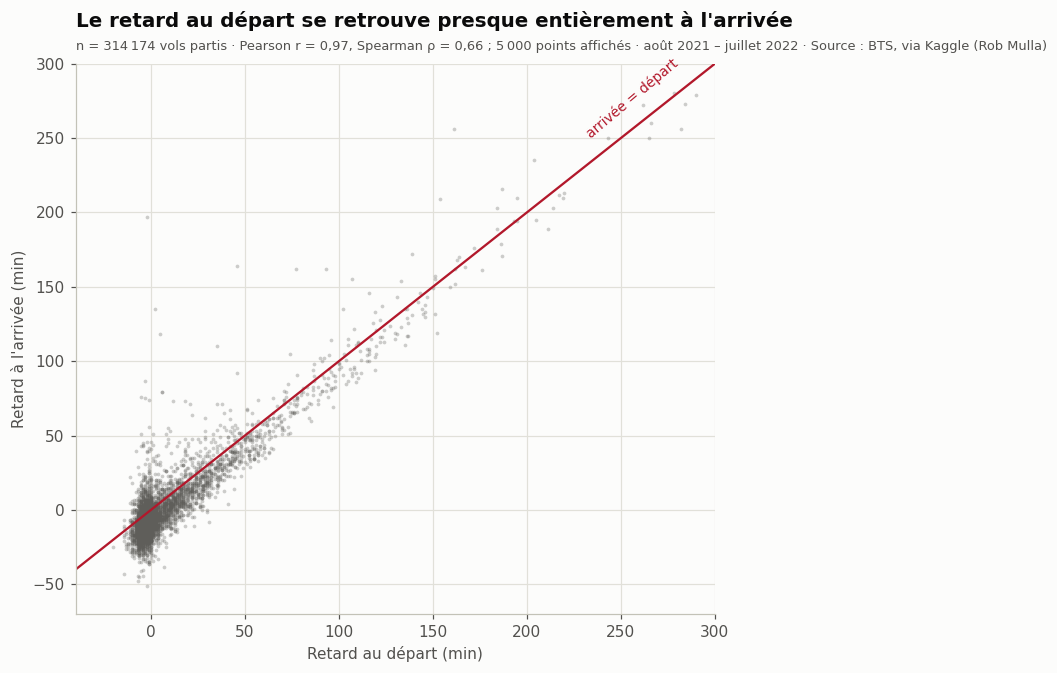

In [32]:
figures.f12_depart_arrivee(vols); plt.show()

> **Question.** Le retard au départ se retrouve-t-il à l'arrivée ?
>
> **Ce que l'on observe.** Les points suivent la droite « arrivée = départ ». Pearson r = 0,97, mais Spearman ρ = 0,66.
>
> **Interprétation.** Les gros retards au départ se reportent presque minute pour minute à l'arrivée : le retard se joue au départ. L'écart entre les deux coefficients est instructif : Pearson est tiré vers 1 par les très gros retards, alors que pour les petits écarts (quelques minutes), l'ordre à l'arrivée dépend aussi du roulage et du vol.
>
> **Limites.** Relation en partie mécanique : le retard à l'arrivée contient le retard au départ. Ce n'est pas une découverte causale.
>
> **Lien avec la question principale.** Justifie d'étudier la ponctualité AU DÉPART pour comparer les compagnies.

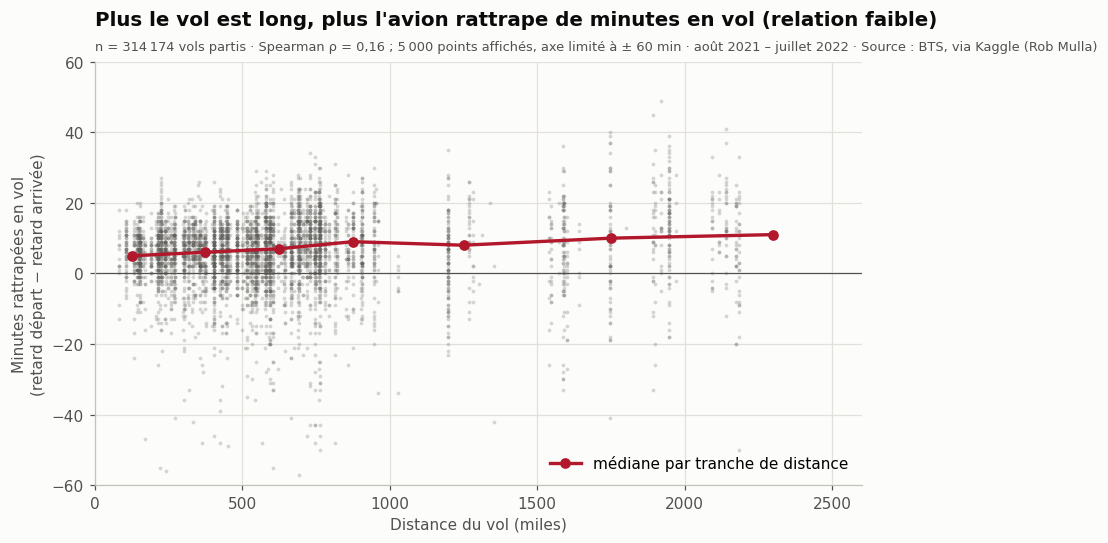

In [33]:
figures.f13_distance_rattrapage(vols); plt.show()

> **Question.** Les vols longs rattrapent-ils plus de retard en vol ?
>
> **Ce que l'on observe.** La médiane des minutes rattrapées augmente avec la distance, mais la relation est faible (Spearman ρ = 0,16) et la dispersion très grande.
>
> **Interprétation.** Un vol long laisse plus de temps pour rattraper. Une explication possible est la marge ajoutée aux horaires des vols longs (« rembourrage » des horaires, étudié dans la littérature) : c'est une **hypothèse**, nos données ne permettent pas de la vérifier.
>
> **Limites.** Relation faible ; r ≈ 0 ne voudrait pas dire « aucun lien », seulement « pas de lien linéaire » (guide, étape 13).
>
> **Lien avec la question principale.** Q1 : le rattrapage en vol fait partie du profil des compagnies (section 8.1).

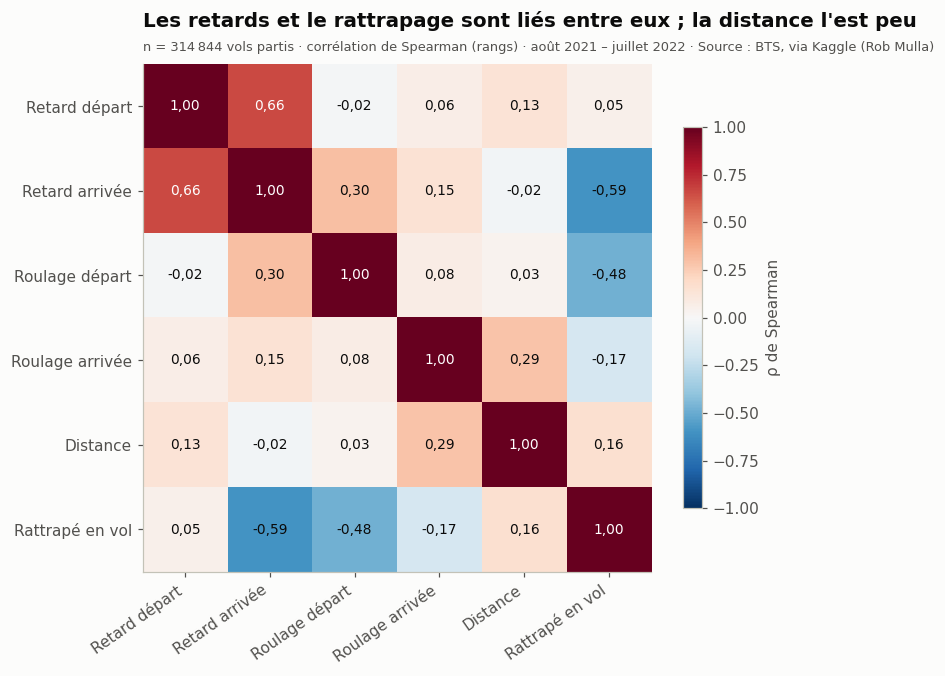

In [34]:
figures.f14_correlations(vols); plt.show()

> **Question.** Quelles variables numériques évoluent ensemble ?
>
> **Ce que l'on observe.** Retard départ ↔ arrivée : ρ = 0,66 ; rattrapé en vol ↔ retard arrivée : -0,59 ; rattrapé ↔ roulage au départ : -0,48 ; la distance est peu liée aux autres variables (au plus 0,29).
>
> **Interprétation.** Un long roulage au départ a lieu APRÈS la mesure du retard au départ (à la porte) : il s'ajoute au retard à l'arrivée et réduit donc le « rattrapage ». Plusieurs liens sont ainsi en partie mécaniques, parce que les variables sont construites les unes à partir des autres.
>
> **Limites.** Corrélation ≠ causalité ; seulement 6 variables choisies pour la question (le cahier interdit la heatmap de toutes les colonnes).
>
> **Lien avec la question principale.** Prépare l'analyse multivariée : quelles variables entrent dans le profil des compagnies.

### 7.4 Vol précédent × vol suivant : l'effet domino (Q4, ancienne problématique)

In [35]:
effet_domino_par_compagnie(vols)

,pct_si_precedent_a_l_heure,pct_si_precedent_en_retard,n_vol_precedent_en_retard,ecart_points
compagnie,,,,
Delta,16.5,40.0,13712.0,23.5
Endeavor (Delta Connection),8.7,29.2,2108.0,20.5
Frontier,26.5,66.7,457.0,40.3
Spirit,20.7,57.5,355.0,36.7
Southwest,33.4,67.6,315.0,34.2
Republic,10.0,41.0,117.0,31.1
SkyWest,16.7,69.1,97.0,52.3
JetBlue,33.3,78.8,33.0,45.5


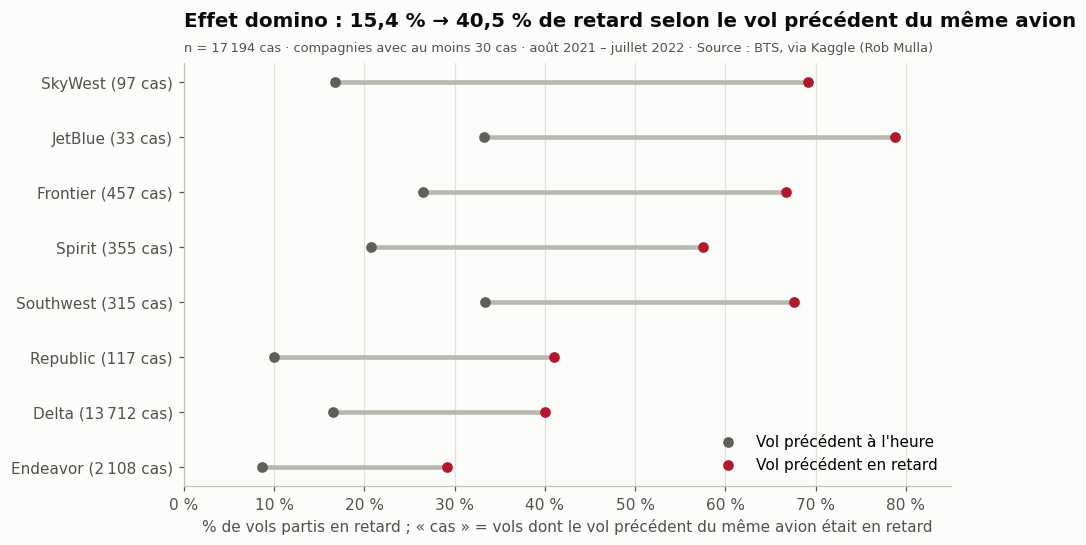

In [36]:
figures.f10_domino(vols); plt.show()

> **Question.** Le retard d'un vol se transmet-il au vol suivant du même avion ?
>
> **Ce que l'on observe.** 40,5 % de retard quand le départ précédent du même avion (même jour) était en retard, contre 15,4 % sinon. L'écart existe pour chacune des 8 compagnies mesurables.
>
> **Interprétation.** H4 est confirmée comme **association forte et régulière**. Elle est cohérente avec la cause officielle « avion arrivé en retard » de la BTS, mais nos données ne permettent pas de la prouver.
>
> **Limites.** Le « vol précédent » est le départ précédent d'Atlanta (pas le vol qui ramène l'avion) ; l'effet n'est mesurable que pour les compagnies dont les avions partent plusieurs fois par jour d'Atlanta (Delta : 13 712 cas).
>
> **Lien avec la question principale.** Q4 : l'ancienne problématique, confirmée sur 12 mois et détaillée par compagnie.

**Zoom été 2022 (version 1 du projet).** Sur juin-juillet 2022 seulement : 54 461 vols, 26,2 % en retard,
effet domino 24,1 % → 50,0 %.
Ces chiffres sont identiques à la version 1 (vérifié par un test automatique) : le passage à 12 mois ne casse rien,
il montre que l'été surestimait le niveau annuel (18,6 %).

**Une objection, et sa réponse.** Si le retard se transmet, le 3e départ d'un avion devrait être plus en retard que le 1er.
Or, par rang de départ d'Atlanta : 18,2 % (1er), 19,0 % (2e), 19,1 % (3e) — presque pareil.

**Explication :** notre fichier ne contient que les **départs d'Atlanta**. Un « 1er départ d'Atlanta » n'est pas le 1er vol
de la journée de l'avion : 31,2 % de ces départs ont lieu après 14 h, l'avion a déjà volé
ailleurs (vols absents de nos données). Le soir, ces « premiers départs » ont 33,4 % de
retard. Le rang est donc une **mauvaise mesure** de la position dans la journée.

**Le domino, lui, tient à chaque heure** (le matin est exclu : seulement 9 cas) :

| Tranche horaire | Vol précédent à l'heure | Vol précédent en retard |
|---|---|---|
| Après-midi (14-18 h) | 14,7 % | 40,7 % |
| Midi (10-14 h) | 13,2 % | 41,6 % |
| Soir (après 18 h) | 16,6 % | 40,2 % |

### 7.5 Bilan du bivarié : quelle variable est la plus liée au retard ?

Chaque lien est mesuré avec l'outil adapté au type des deux variables. Les mesures ne sont pas identiques, mais elles vont
toutes de 0 (aucun lien) à 1 : on peut comparer leurs ordres de grandeur.

In [37]:
from approfondissement import liens_bivaries
pd.DataFrame(liens_bivaries(vols)).T[["type", "mesure", "valeur"]]

,type,mesure,valeur
compagnie × retard (min),catégorielle × numérique,epsilon² (Kruskal-Wallis),0.04
type × retardé ou annulé,catégorielle × catégorielle,V de Cramér,0.133
tranche horaire × en retard,catégorielle × catégorielle,V de Cramér,0.136
jour de la semaine × en retard,catégorielle × catégorielle,V de Cramér,0.062
saison × en retard,catégorielle × catégorielle,V de Cramér,0.107
compagnie × classe de retard,catégorielle × catégorielle,V de Cramér,0.112
retard départ × retard arrivée,numérique × numérique,rho de Spearman,0.658
heure de départ × retard (min),numérique × numérique,rho de Spearman,0.143
distance × retard (min),numérique × numérique,rho de Spearman,0.103
distance × minutes rattrapées,numérique × numérique,rho de Spearman,0.157


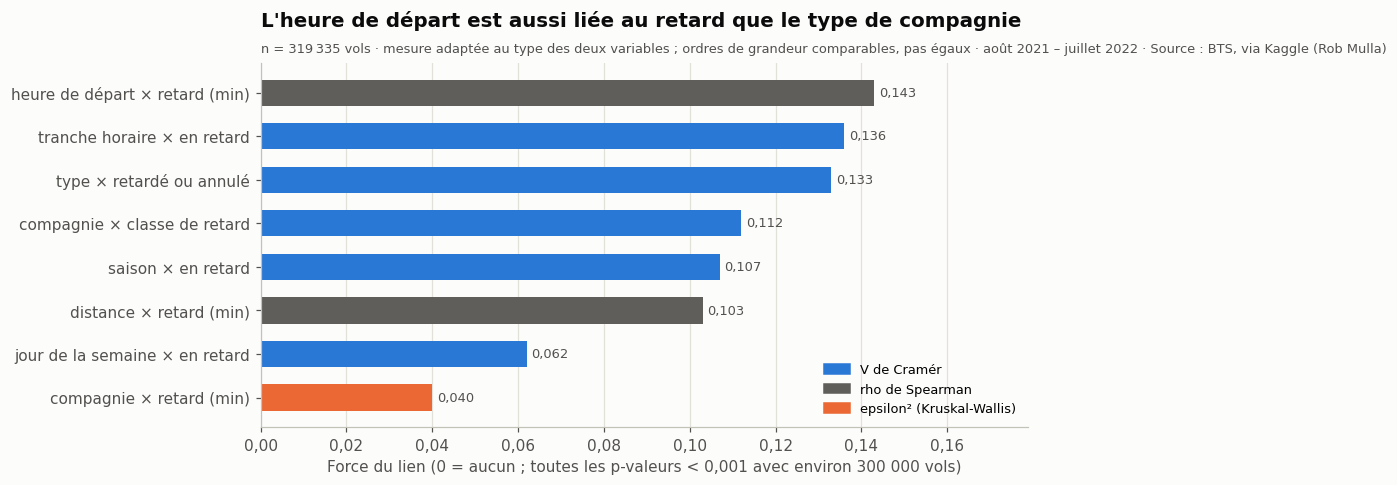

In [38]:
figures.f21_force_des_liens(vols); plt.show()

> **Question.** Parmi les variables étudiées, lesquelles sont le plus liées au retard ?
>
> **Ce que l'on observe.** Heure de départ (ρ = 0,143), tranche horaire (V = 0,136) et type de compagnie (V = 0,133) arrivent en tête ; la saison suit (V = 0,107) ; le jour de la semaine est le plus faible (V = 0,062).
>
> **Interprétation.** **Quand** on vole compte autant que **avec qui** on vole. C'est la justification chiffrée de la standardisation (section 8.3) : comparer les compagnies sans tenir compte de l'heure serait injuste.
>
> **Limites.** Tous les liens sont faibles (moins de 0,2) : le retard dépend de beaucoup de facteurs absents du fichier (météo, contrôle aérien). Mesures différentes : on compare des ordres de grandeur, pas des valeurs exactes.
>
> **Lien avec la question principale.** Q2 : hiérarchise les facteurs associés au retard.

### 7.6 Météo × retard (fusion avec Open-Meteo)

Grâce à la fusion, l'hypothèse « les orages » devient une **mesure**. Un point = un jour.

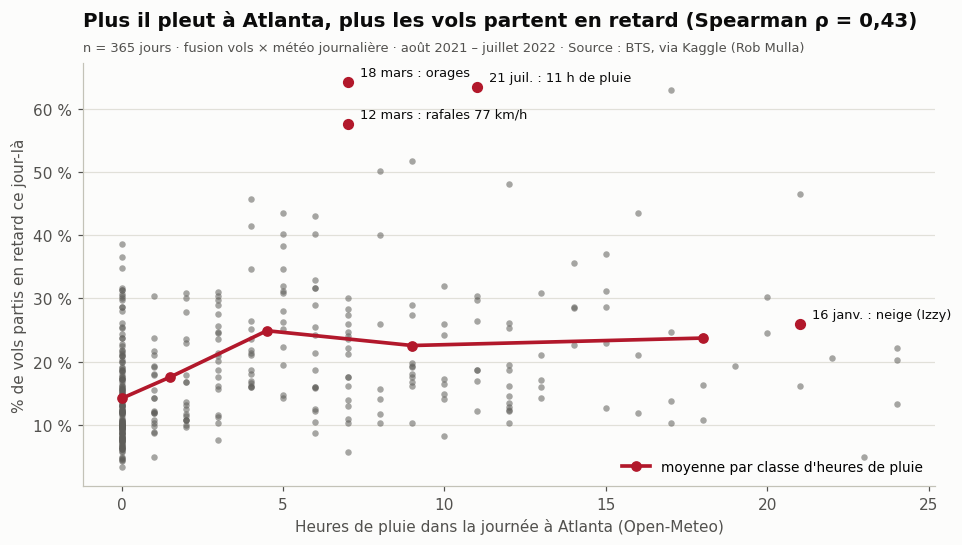

In [39]:
figures.f22_meteo_retard(vols); plt.show()

In [40]:
lire('jour')[['pct_retard', 'pluie_mm', 'heures_de_pluie', 'rafales_max_kmh', 'neige_cm']].corr(method='spearman')['pct_retard'].round(2)

pct_retard         1.00
pluie_mm           0.45
heures_de_pluie    0.43
rafales_max_kmh    0.28
neige_cm           0.13
Name: pct_retard, dtype: float64

> **Question.** La météo d'Atlanta est-elle liée au retard du jour ?
>
> **Ce que l'on observe.** Oui : 14,1 % de retard un jour sec, 24,5 % un jour de forte pluie ; ρ = 0,43 avec les heures de pluie.
>
> **Interprétation.** Les deux jours que la presse n'expliquait pas sont expliqués par la météo : le 2022-03-12, rafales à 77 km/h ; le 2022-07-21, 11 heures de pluie (médiane de l'année : 2 h).
>
> **Limites.** Météo d'Atlanta seulement : un orage à l'arrivée (New York, Floride) n'est pas mesuré.
>
> **Lien avec la question principale.** Q2 et Q4 : une partie du retard est liée à des conditions extérieures, pas à la compagnie.

### 7.7 Destination × retard

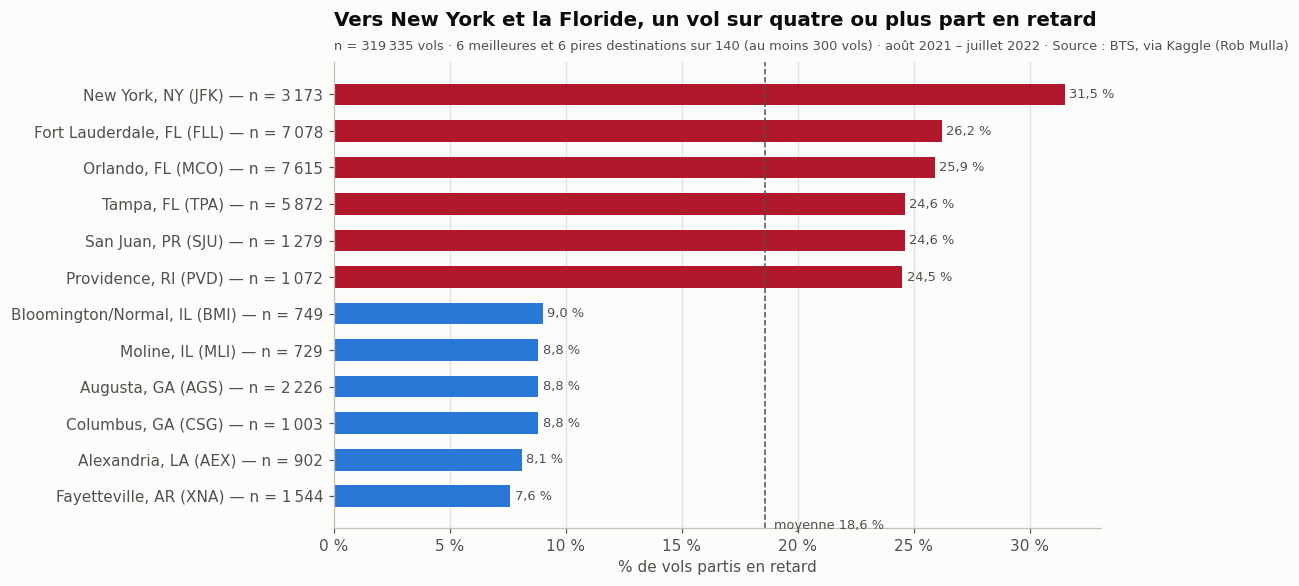

In [41]:
figures.f25_destinations(vols); plt.show()

> **Question.** Certaines destinations sont-elles plus en retard ?
>
> **Ce que l'on observe.** Vers New York JFK, 31,5 % des vols partent en retard ; vers la Floride, environ un sur quatre ; vers Fayetteville, AR, 7,6 %.
>
> **Interprétation.** Les destinations congestionnées (New York, Floride) sont aussi celles des compagnies à bas coût.
>
> **Limites.** Non standardisé par compagnie et par heure : c'est une **piste**.
>
> **Lien avec la question principale.** Ouvre une nouvelle dimension, grâce à la table `destinations`.

## 8. Analyse multivariée : plusieurs variables à la fois

Les relations à deux variables peuvent tromper quand une troisième variable intervient (variable de confusion,
effet de composition). On combine donc compagnie, indicateurs, heure, mois et saison.

### 8.1 Le profil complet des compagnies (14 compagnies × 7 indicateurs)

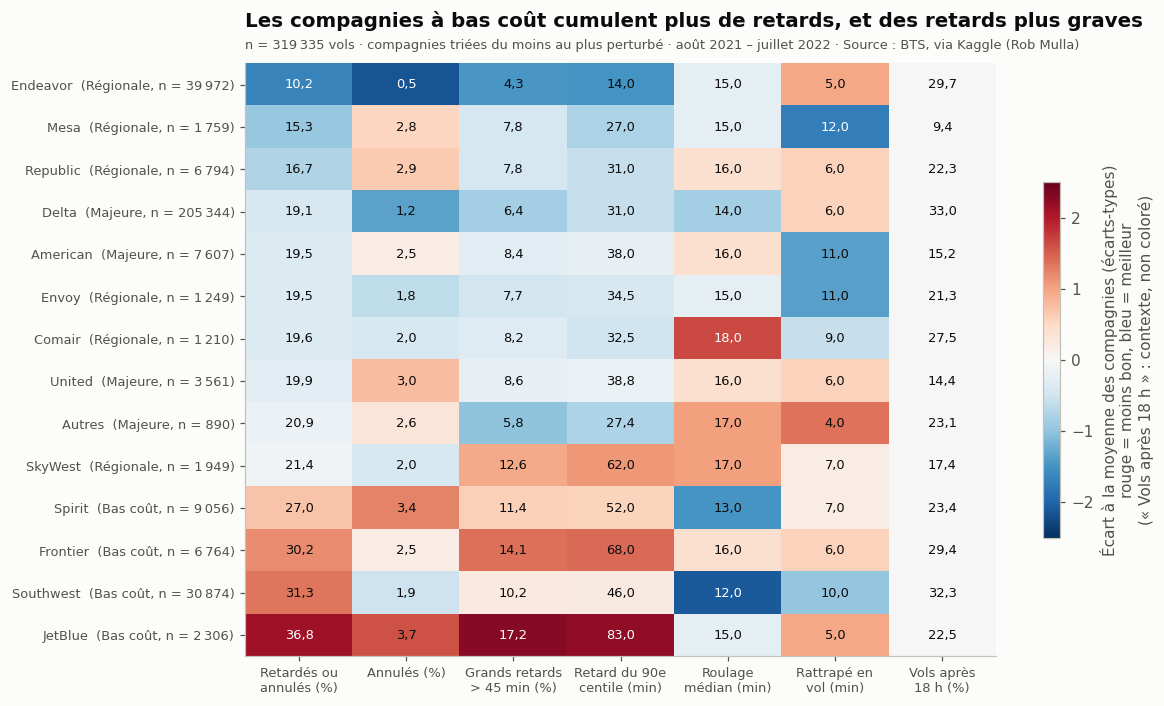

In [42]:
figures.f05_profil_compagnies(vols); plt.show()

> **Question.** Les compagnies diffèrent-elles aussi en gravité, fiabilité et exploitation ?
>
> **Ce que l'on observe.** Les compagnies à bas coût cumulent fréquence et gravité (ex. JetBlue : 17,2 % de grands retards, 90e centile à 83 min). Endeavor est la plus régulière (0,5 % d'annulations).
>
> **Interprétation.** Le profil multivarié montre que « ponctualité » n'est pas une seule dimension : fréquence, gravité et annulations ne vont pas toujours ensemble.
>
> **Limites.** La couleur compare chaque compagnie à la moyenne des compagnies (non pondérée) ; « vols après 18 h » est une information de contexte, non colorée.
>
> **Lien avec la question principale.** Q1 (profils) et prépare Q2 : la part de vols du soir diffère selon les compagnies.

**Plusieurs versions de la classification (principe « multi-versions » du plan de travail).** Le type « bas coût » est un choix
(JetBlue est parfois dite « hybride »). On vérifie que la conclusion ne dépend pas de ce choix, ni d'une seule grosse compagnie :

| Version | Bas coût | Majeures | Régionales | Ordre conservé ? |
|---|---|---|---|---|
| A : classification retenue | 30,6 % | 19,1 % | 12,1 % | oui |
| B : JetBlue classée majeure (« hybride ») | 30,3 % | 19,3 % | 12,1 % | oui |
| C : sans la plus grosse compagnie de chaque type | 29,4 % | 19,7 % | 17,8 % | oui |

> **Lecture.** L'ordre « bas coût > majeures > régionales » tient dans les trois versions : la conclusion est **robuste**.
> Mais la version C apporte une **nuance importante** : sans Endeavor (3 vols régionaux sur 4), les régionales passent de
> 12,1 % à 17,8 %, proches des majeures
> (19,7 %). **L'avantage des régionales est surtout celui d'Endeavor.** Phrase licite : *les compagnies à bas
> coût sont nettement derrière ; Endeavor est nettement devant ; les autres régionales et les majeures sont proches.*

### 8.2 Jour × heure × retard

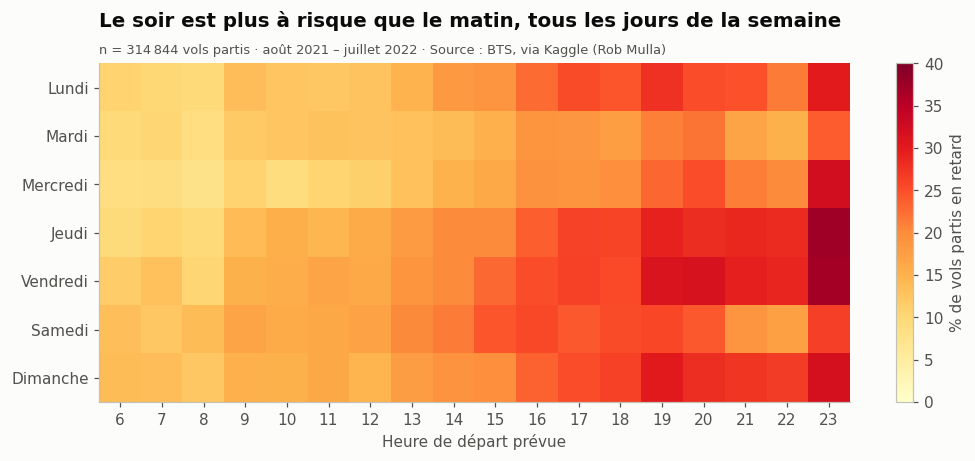

In [43]:
figures.f11_jour_heure(vols); plt.show()

> **Question.** Le motif « matin calme, soir à risque » vaut-il pour tous les jours ?
>
> **Ce que l'on observe.** Le % de vols en retard augmente du matin au soir sur chacune des 7 lignes : le motif se retrouve tous les jours de la semaine.
>
> **Interprétation.** Hypothèse cohérente avec H4 : les retards de la journée s'accumulent. L'heure est donc une **variable de composition** à neutraliser quand on compare les compagnies (Q2).
>
> **Limites.** Association, pas causalité ; les heures très tôt et très tard ont moins de vols (plus de variabilité).
>
> **Lien avec la question principale.** Prépare Q2 (effet de composition) et Q4 (effet domino).

### 8.3 Compagnie × heure × mois : facteurs associés et effets de composition (Q2)

**Standardisation directe.** On calcule le % de retard qu'aurait chaque compagnie si elle avait **la même répartition**
(par tranche horaire, ou par mois) que l'ensemble des vols : `taux standardisé = Σ poids_strate × taux_dans_la_strate`
(même formule que la moyenne globale du guide : x̄ = Σ w_h μ_h). Si l'écart brut / standardisé est grand, la **composition**
(quand la compagnie vole) explique une partie de sa différence apparente.

In [44]:
comparaison_brut_standardise(vols, 'tranche_horaire')

,pct_retard_brut,taux_standardise_pct,ecart_points,rang_brut,rang_standardise,couverture_pct
compagnie,,,,,,
JetBlue,34.4,37.4,3.0,1,1,100.0
Southwest,29.9,31.1,1.2,2,2,100.0
Frontier,28.4,28.7,0.3,3,3,100.0
Spirit,24.4,25.7,1.3,4,4,100.0
SkyWest,19.8,21.3,1.5,5,5,100.0
Autres,18.8,16.3,-2.5,6,11,100.0
Delta,18.1,17.9,-0.2,7,8,100.0
Envoy,18.0,17.8,-0.2,8,9,100.0
Comair,18.0,17.1,-0.9,9,10,100.0


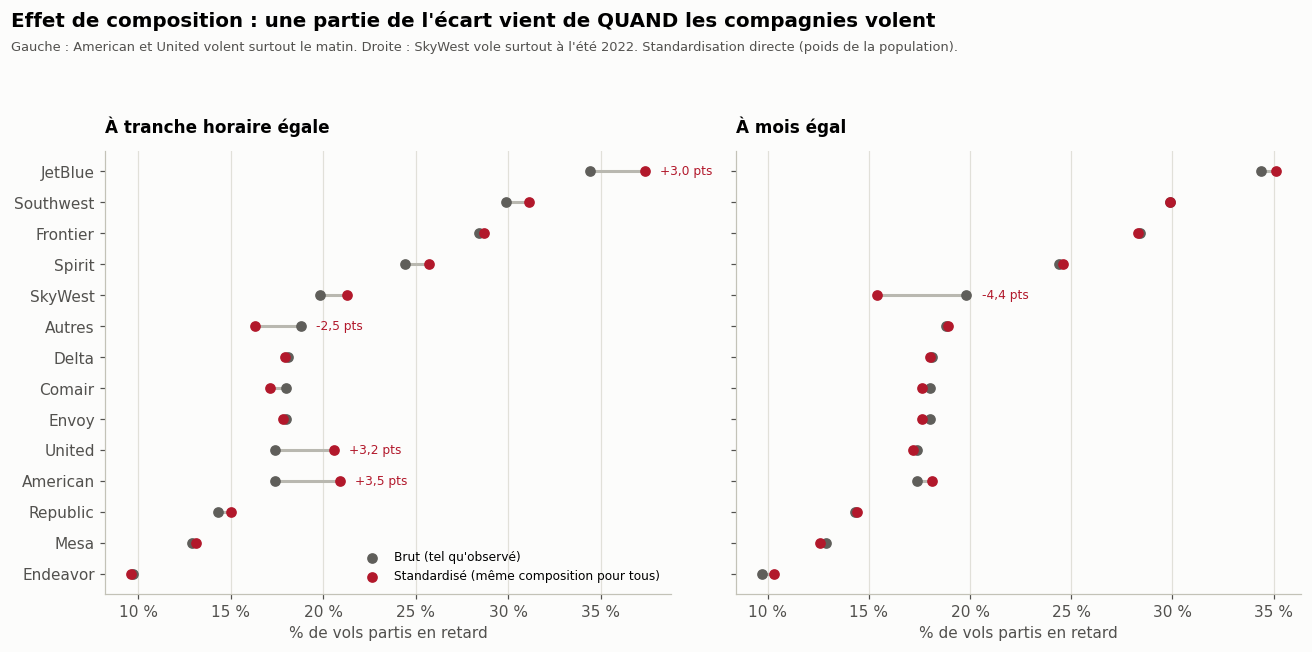

In [45]:
figures.f07_composition(vols); plt.show()

> **Question.** Les écarts entre compagnies viennent-ils de quand elles volent ?
>
> **Ce que l'on observe.** À tranche horaire égale, American passe de 17,4 % à 20,9 % (rang 10 → 6) : elle vole surtout le matin. À mois égal, SkyWest passe de 19,8 % à 15,4 % (rang 5 → 11) : elle vole surtout à l'été 2022. Delta change très peu.
>
> **Interprétation.** H2 est confirmée pour certaines compagnies : une partie de leur différence apparente est un **effet de composition**. Pour les grands écarts (bas coût contre régionales), la standardisation ne change pas le classement.
>
> **Limites.** On ne neutralise que les variables mesurées (heure, mois) ; d'autres facteurs (destinations, type d'avion) restent possibles.
>
> **Lien avec la question principale.** Q2 : distingue ce qui tient à la compagnie de ce qui tient à son programme de vols.

In [46]:
globale, par_compagnie = correlation_globale_et_par_groupe(vols, "TaxiOut", "DepDelayMinutes")
print(f"Corrélation globale roulage-retard : {globale:.3f}")
par_compagnie

Corrélation globale roulage-retard : 0.002


,correlation,n
compagnie,,
American,0.049,7417.0
Autres,0.001,867.0
Comair,0.017,1186.0
Delta,0.038,202859.0
Endeavor (Delta Connection),0.075,39759.0
Envoy,0.067,1226.0
Frontier,0.047,6598.0
JetBlue,0.037,2221.0
Mesa,0.078,1710.0


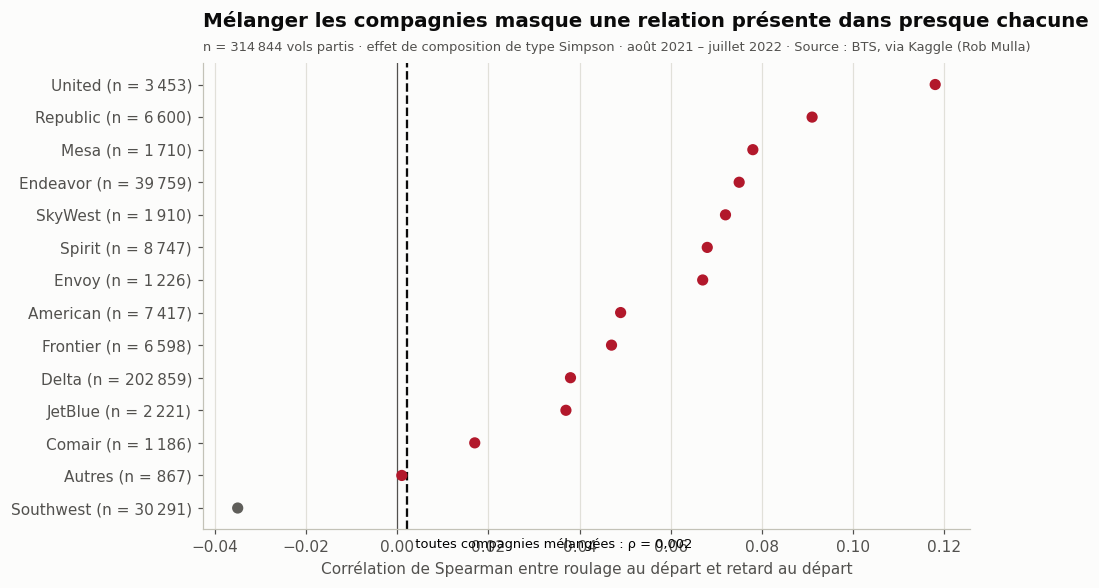

In [47]:
figures.f09_roulage_retard_simpson(vols); plt.show()

> **Question.** La relation entre roulage et retard est-elle la même quand on mélange les compagnies ?
>
> **Ce que l'on observe.** Toutes compagnies mélangées, ρ = 0,002 (aucune relation apparente). À l'intérieur des compagnies, la corrélation est positive pour 13 compagnies sur 14.
>
> **Interprétation.** Effet de composition **de type Simpson** : mélanger des groupes qui diffèrent à la fois par leur roulage et leur niveau de retard masque une relation présente dans presque chacun. Ce n'est pas une inversion complète : on parle d'un **signal** à analyser, pas d'une preuve.
>
> **Limites.** Les corrélations sont faibles (moins de 0,12) : le roulage n'explique qu'une très petite part du retard.
>
> **Lien avec la question principale.** Q2 : montre pourquoi il faut analyser **par compagnie** avant de conclure sur une relation globale.

### 8.4 Compagnie × saison : le classement change-t-il ? (Q3)

In [48]:
taux_par_compagnie_et_periode(vols, 'saison')[0]

saison,Automne,Hiver,Printemps,Été
compagnie,,,,
American,15.2,12.0,17.1,26.9
Autres,15.3,20.4,24.5,16.7
Comair,11.7,16.2,19.7,22.9
Delta,12.0,15.8,20.9,23.1
Endeavor (Delta Connection),5.8,9.1,11.5,13.8
Envoy,14.7,14.2,15.3,27.0
Frontier,17.8,25.2,38.1,32.9
JetBlue,29.4,37.9,33.3,38.0
Mesa,13.4,16.7,9.7,11.0


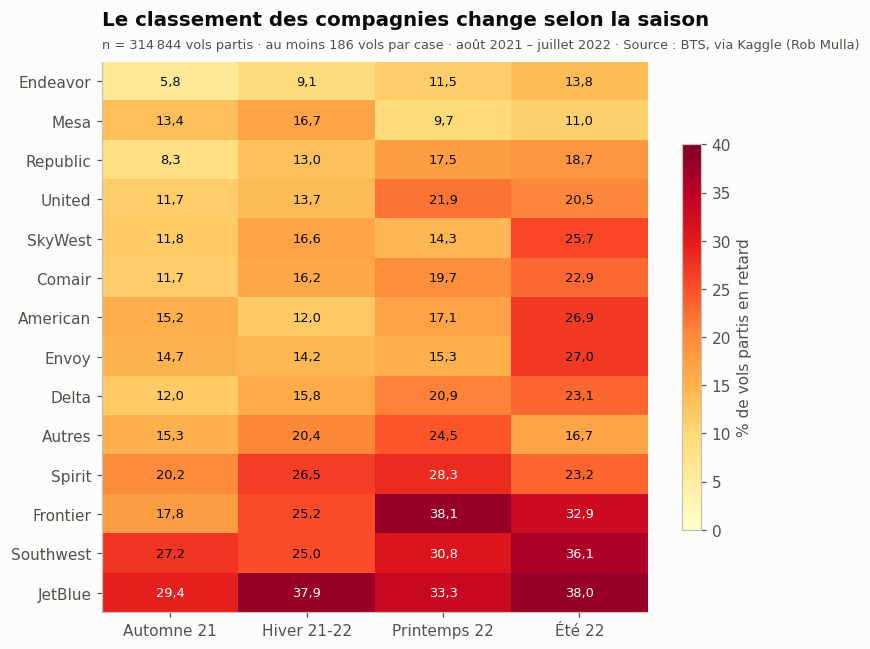

In [49]:
figures.f08_compagnies_par_saison(vols); plt.show()

> **Question.** Le classement des compagnies est-il stable selon la saison ?
>
> **Ce que l'on observe.** Spirit : 26,5 % en hiver, 23,2 % en été ; American : 12,0 % en hiver, 26,9 % en été. La plus ponctuelle selon la saison : automne Endeavor, hiver Endeavor, printemps Mesa, été Mesa ; la moins ponctuelle : automne JetBlue, hiver JetBlue, printemps Frontier, été JetBlue.
>
> **Interprétation.** H3 est confirmée pour le milieu du classement : juger les compagnies sur une seule saison peut inverser leur ordre.
>
> **Limites.** Une seule année ; les petites compagnies ont peu de vols par saison (cases plus fragiles).
>
> **Lien avec la question principale.** Q3 : justifie le passage de 2 mois à 12 mois.

### 8.5 Compagnie × semaine × annulations : chaque compagnie a ses propres crises

Trois variables : la compagnie, le temps (la semaine) et le % de vols annulés. Ce graphique relie les chiffres au monde réel.

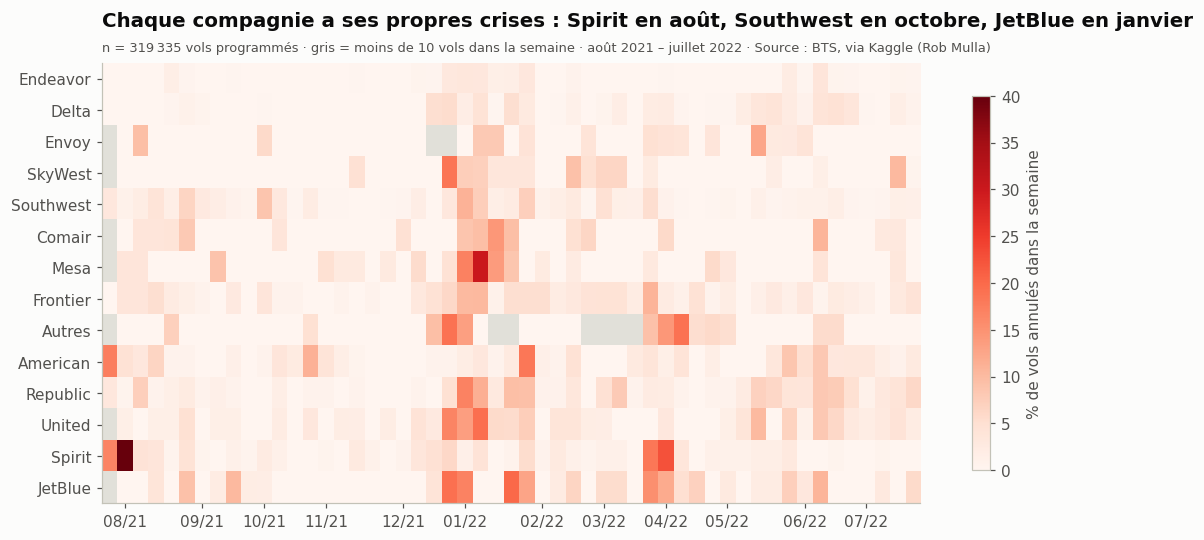

In [50]:
figures.f20_annulations_compagnie_semaine(vols); plt.show()

> **Question.** Les crises touchent-elles toutes les compagnies en même temps ?
>
> **Ce que l'on observe.** Non. Spirit s'effondre début août 2021 (79,1 % de vols annulés du 2021-08-02 au 2021-08-05, contre 2,5 % le reste de l'année), Southwest en octobre, American le week-end d'Halloween et début février, JetBlue fin janvier. Seuls Noël 2021 et la tempête du 16 janvier touchent presque tout le monde.
>
> **Interprétation.** Une partie des crises vient de **l'extérieur d'Atlanta** : le blizzard de Boston et New York (JetBlue), le vent et le verglas à Dallas (American), le contrôle aérien en Floride (Southwest). Une compagnie dont les bases sont ailleurs subit à Atlanta des problèmes nés loin d'Atlanta.
>
> **Limites.** Les causes viennent des sources citées ; nos données montrent seulement les jours et l'ampleur.
>
> **Lien avec la question principale.** Q1 et Q3 : une partie de l'écart entre compagnies vient de quelques crises, pas d'un défaut régulier.

### 8.6 Le modèle : tous les facteurs ensemble (travail du data scientist)

Les analyses une à une mélangent les facteurs (JetBlue vole le soir, en été...). Une **régression logistique** les met tous
ensemble : compagnie, heure, saison, jour, vol précédent du même avion, pluie et rafales au départ (vue `v_depart_meteo`).
Chaque **rapport de cotes** se lit « à conditions égales » par rapport à la référence (Delta, matin, automne, mardi, avion à l'heure).

In [51]:
import modele
resultat = modele.ajuster()   # environ 1 minute : modèle complet + un modèle sans chaque bloc
print(f"n = {resultat['n']} vols partis ; pseudo-R² = {resultat['pseudo_r2']:.3f} ; AUC = {resultat['auc']:.3f}")
resultat["rapports"].round(2)

n = 314844 vols partis ; pseudo-R² = 0.079 ; AUC = 0.692


,rapport_de_cotes,ic_bas,ic_haut,p_valeur
Compagnie : American,1.08,1.01,1.15,0.02
Compagnie : Autres,1.00,0.84,1.20,0.96
Compagnie : Comair,0.86,0.73,1.00,0.04
Compagnie : Endeavor (Delta Connection),0.52,0.50,0.54,0.00
Compagnie : Envoy,0.79,0.68,0.92,0.00
Compagnie : Frontier,1.82,1.72,1.93,0.00
Compagnie : JetBlue,2.65,2.42,2.91,0.00
Compagnie : Mesa,0.69,0.60,0.80,0.00
Compagnie : Republic,0.75,0.70,0.81,0.00
Compagnie : SkyWest,1.05,0.93,1.18,0.45


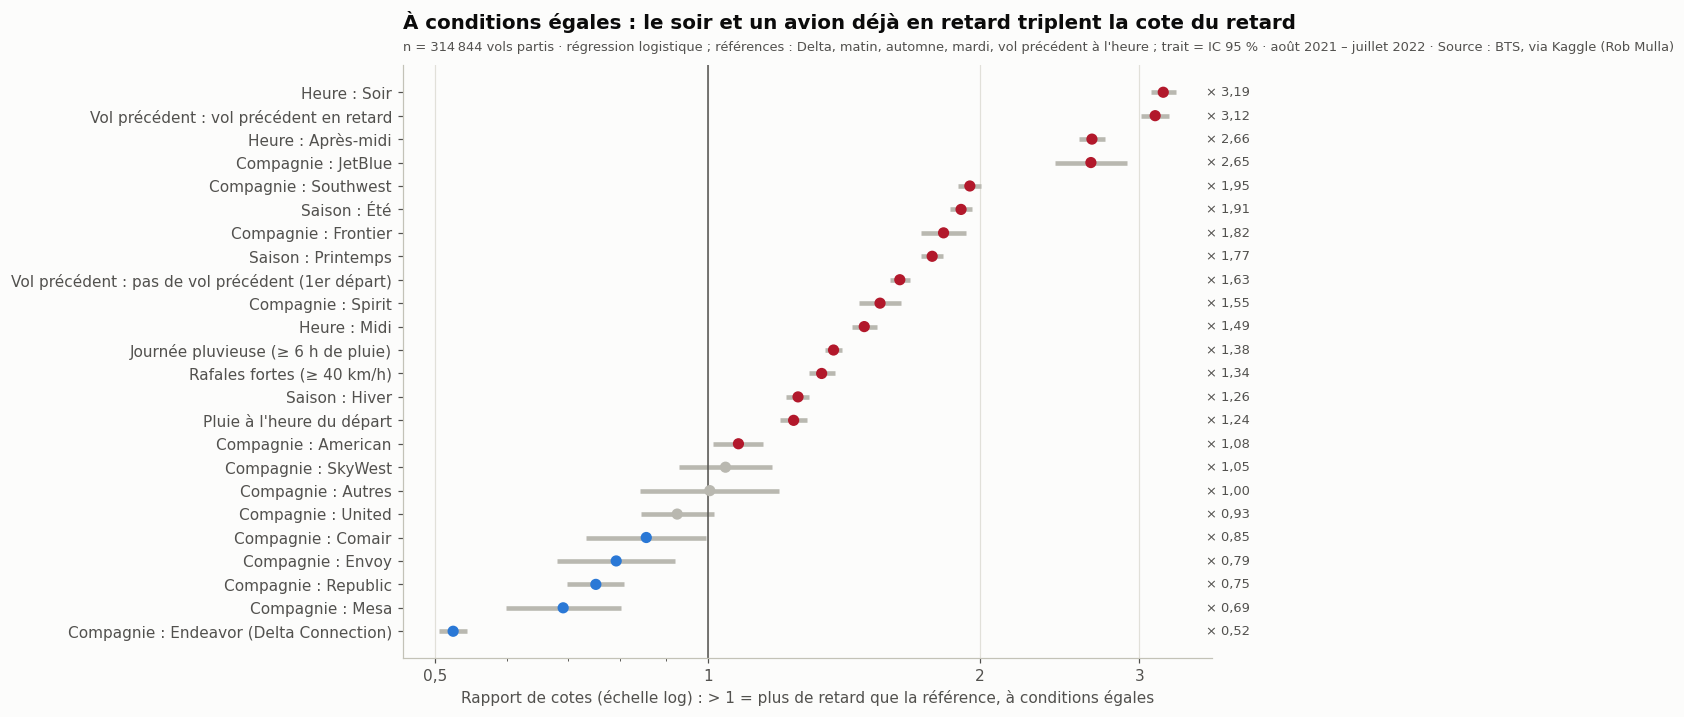

In [52]:
figures.f23_modele_rapports(vols); plt.show()

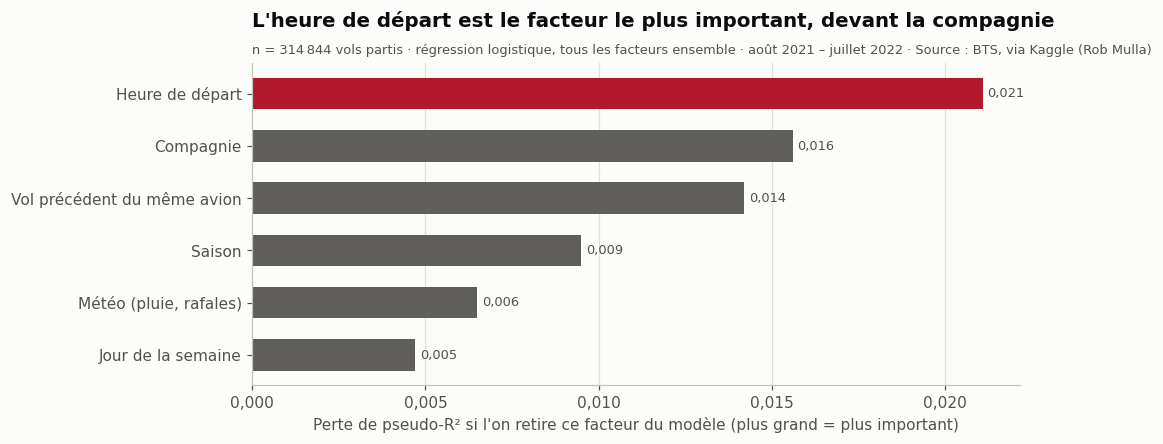

In [53]:
figures.f24_importance_facteurs(vols); plt.show()

> **Question.** Quand on met tous les facteurs ensemble, qu'est-ce qui pèse le plus ?
>
> **Ce que l'on observe.** Partir le soir multiplie la cote du retard par 3,19 ; un avion déjà en retard, par 3,12 ; JetBlue, par 2,65 (vs Delta) ; Endeavor la divise presque par deux (0,52). L'heure est le bloc le plus important, devant la compagnie.
>
> **Interprétation.** Du meilleur au pire vol possible : 1,6 % (Endeavor, mardi matin d'automne, temps sec, avion à l'heure) à 81,5 % (JetBlue, vendredi soir d'été, pluie, avion déjà en retard).
>
> **Limites.** AUC = 0,69, pseudo-R² = 0,079 : le modèle n'explique qu'une partie du retard ; associations, pas causes.
>
> **Lien avec la question principale.** Q1 et Q2 : les compagnies diffèrent même à conditions égales, mais l'heure pèse plus.

## 9. Échantillonnage (partie 2) : les conclusions résistent-elles ? (Q5)

Maintenant que les analyses ont établi les conclusions de l'étude, on vérifie si un échantillon de 5 000 vols les
retrouve, avec chaque méthode (100 tirages), puis avec d'autres tailles.

### 9.1 E3 — Les relations entre deux variables sont-elles conservées ?

**Question** : l'effet domino, le profil « retard par heure » et la relation retard au départ / retard à l'arrivée
restent-ils les mêmes ? **Colonnes** : `vol_precedent_en_retard` × `DepDel15`, `heure_depart_prevue` × `DepDel15`,
`DepDelay` × `ArrDelay`.

In [54]:
resume[['E3_erreur_ecart_domino', 'E3_ecart_moyen_profil_horaire', 'E3_erreur_corr_depart_arrivee']].round(3).sort_values('E3_erreur_ecart_domino')

,E3_erreur_ecart_domino,E3_ecart_moyen_profil_horaire,E3_erreur_corr_depart_arrivee
Systématique,2.359,2.210,0.006
Aléatoire simple,2.453,2.229,0.006
Temporel (par jour),2.586,2.179,0.006
Répété (bootstrap),2.671,2.189,0.007
Par grappes (jours),5.539,4.507,0.012
Stratifié par compagnie (repondéré),6.200,4.854,0.011
Stratifié par compagnie,10.298,3.794,0.007


> **Réponse.** L'écart domino de la population (25,1
> points) est retrouvé à 2,4 points près en moyenne avec « Systématique », mais à 10,3 points près avec « Stratifié par compagnie ».
> Une relation repose sur un sous-groupe (ici les vols qui ont un vol précédent, environ 40 % des vols) : elle est donc
> plus fragile qu'une moyenne globale. Explication probable du mauvais score du stratifié à part égale : la plupart de ses vols
> viennent de compagnies dont les avions ne repartent presque jamais d'Atlanta le même jour, donc très peu de cas « domino ».
> **À retenir** (guide, étape 8) : *une moyenne peut être stable alors qu'une relation
> est sensible à l'échantillon* — il faut vérifier les deux.

### 9.2 E4 — Les structures à plusieurs variables et la composition sont-elles conservées ?

**Question** : le tableau compagnie × saison est-il retrouvé ? L'effet de composition de la section 8.3 (corrélation
roulage-retard ≈ 0 au global, positive dans les compagnies) est-il conservé, ou créé par la méthode ?
**Colonnes** : `compagnie` × `saison` × `DepDel15` ; `TaxiOut` × `DepDelayMinutes` × `compagnie`.

In [55]:
resume[['E4_erreur_moyenne_compagnie_saison', 'E4_pct_cases_moins_30_vols', 'E4_corr_globale_roulage_retard', 'E4_erreur_corr_par_compagnie']].round(3).sort_values('E4_erreur_moyenne_compagnie_saison')

,E4_erreur_moyenne_compagnie_saison,E4_pct_cases_moins_30_vols,E4_corr_globale_roulage_retard,E4_erreur_corr_par_compagnie
Stratifié par compagnie,3.075,0.054,0.017,0.039
Stratifié par compagnie (repondéré),3.075,0.054,0.005,0.039
Systématique,3.227,66.196,0.001,0.074
Temporel (par jour),3.280,66.161,0.001,0.072
Aléatoire simple,3.316,66.214,0.003,0.074
Répété (bootstrap),3.392,66.107,0.002,0.076
Par grappes (jours),6.888,68.429,0.001,0.083


> **Réponse.** Avec 5 000 vols tirés au hasard, 66 % des cases
> compagnie × saison ont moins de 30 vols : le tableau croisé devient en partie inutilisable. Le stratifié par compagnie
> en laisse beaucoup moins (0 %). Mais, utilisé naïvement,
> il **déplace la corrélation globale** roulage-retard (moyenne 0,017,
> contre 0,002 dans la population), parce qu'il change le poids des compagnies.
> **À retenir** : changer la composition de l'échantillon change toute statistique **globale** — c'est l'effet de composition
> (et le risque de type Simpson) provoqué par la méthode elle-même.

### 9.3 E6 — Les conclusions de la question principale restent-elles vraies ?

C'est l'expérience la plus importante : elle relie l'échantillonnage à la question principale. Pour chacune des 8 conclusions
de l'étude (vraies dans la population), on compte dans combien des 100 tirages elle reste vraie.

In [56]:
pd.Series(CONCLUSIONS, name='Conclusion (vraie dans la population)')

C1       Bas coût > Majeures > Régionales (% de retard)
C2                   Southwest plus en retard que Delta
C3         Endeavor est la compagnie la plus ponctuelle
C4    American paraît plus ponctuelle que Delta, mai...
C5    American < Delta en retard seul, mais > Delta ...
C6            Effet domino : écart de plus de 15 points
C7    Roulage-retard : corrélation globale ≈ 0 mais ...
C8     Le retard est plus fréquent le soir que le matin
Name: Conclusion (vraie dans la population), dtype: object

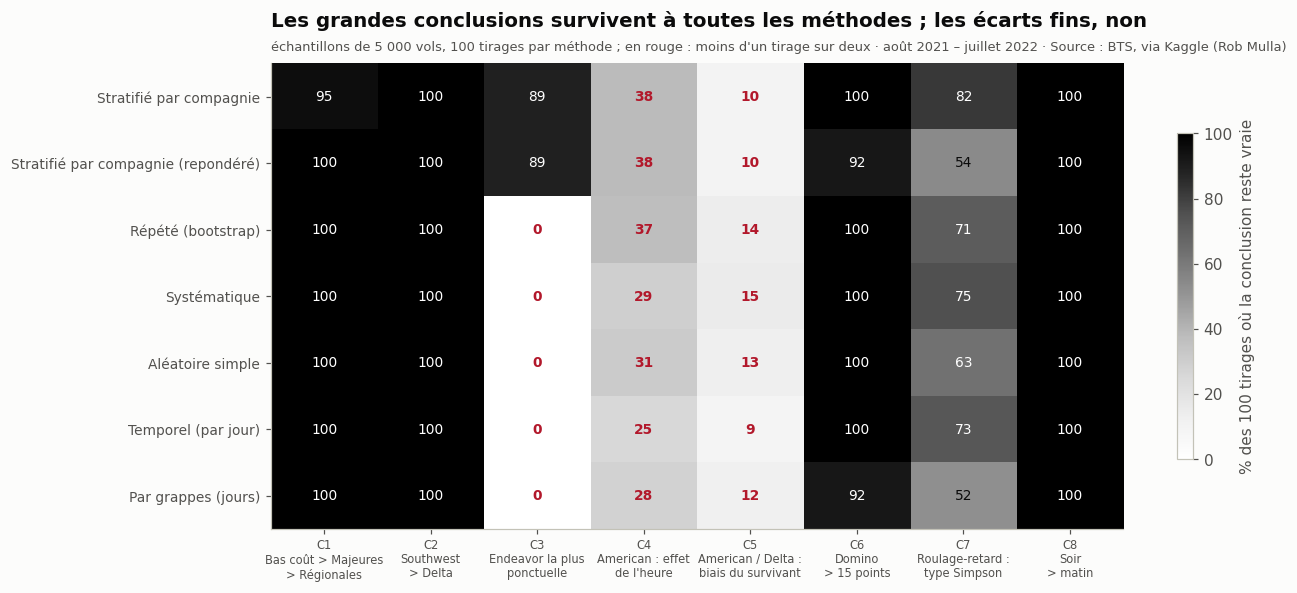

In [57]:
figures.s2_conclusions_par_methode(mesures); plt.show()

> **Réponse.** Les **grandes** conclusions résistent à toutes les méthodes : C1 (bas coût > majeures > régionales),
> C2 (Southwest > Delta), C8 (soir > matin) sont vraies dans presque tous les tirages. Les conclusions **fines** ne résistent pas :
> avec un tirage aléatoire simple, C4 (effet de l'heure pour American) n'est retrouvée que dans 31 %
> des tirages, C5 (biais du survivant American / Delta) dans 13 %, et C3 (« Endeavor la plus
> ponctuelle de toutes ») dans 0 %, parce que des petites compagnies ne sont pas comparables.
> Seul le stratifié à part égale, qui garde assez de vols dans chaque compagnie, retrouve C3
> (89 % des tirages).
> **À retenir** : un échantillon de 5 000 vols permet d'affirmer les grandes différences entre compagnies, pas les petits écarts
> entre compagnies proches. C'est pourquoi les conclusions de la section 10 ont un statut (solide / piste / artefact).

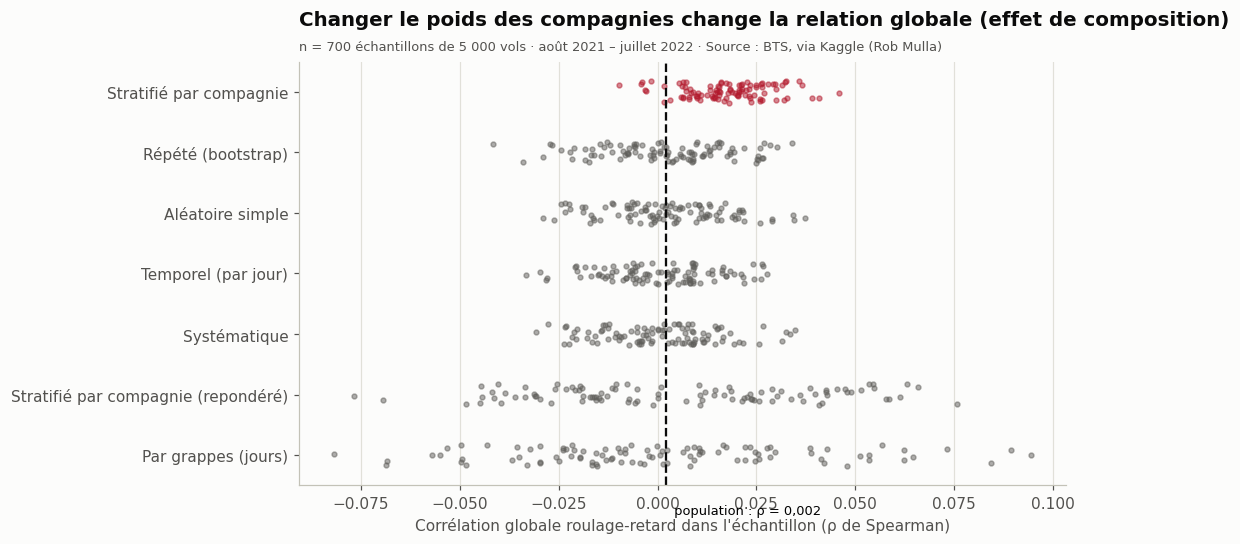

In [58]:
figures.s5_correlation_globale_selon_methode(mesures, globale); plt.show()

### 9.4 Quelle méthode pour quel objectif ?

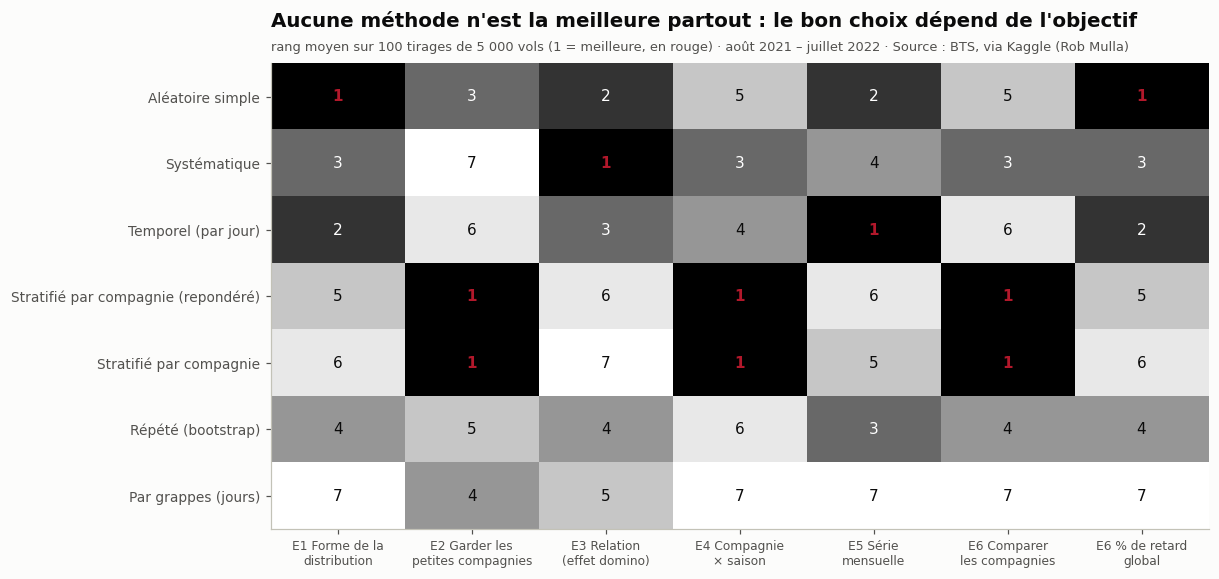

In [59]:
figures.s4_methode_par_objectif(mesures); plt.show()

> **Réponse.** Aucune méthode n'est la meilleure partout (hypothèse H5 confirmée) :
> - pour **décrire la forme** d'une variable : Aléatoire simple ;
> - pour un **chiffre global** (% de retard) : Aléatoire simple ;
> - pour **suivre le temps** (série mensuelle) : Temporel (par jour) ;
> - pour **comparer les compagnies** (notre question principale) : Stratifié par compagnie,
>   à condition de **repondérer** pour tout chiffre global ;
> - les **grappes de jours** sont les moins adaptées presque partout.

### 9.5 E7 — Quelle taille d'échantillon ? (pourquoi 5 000 ?)

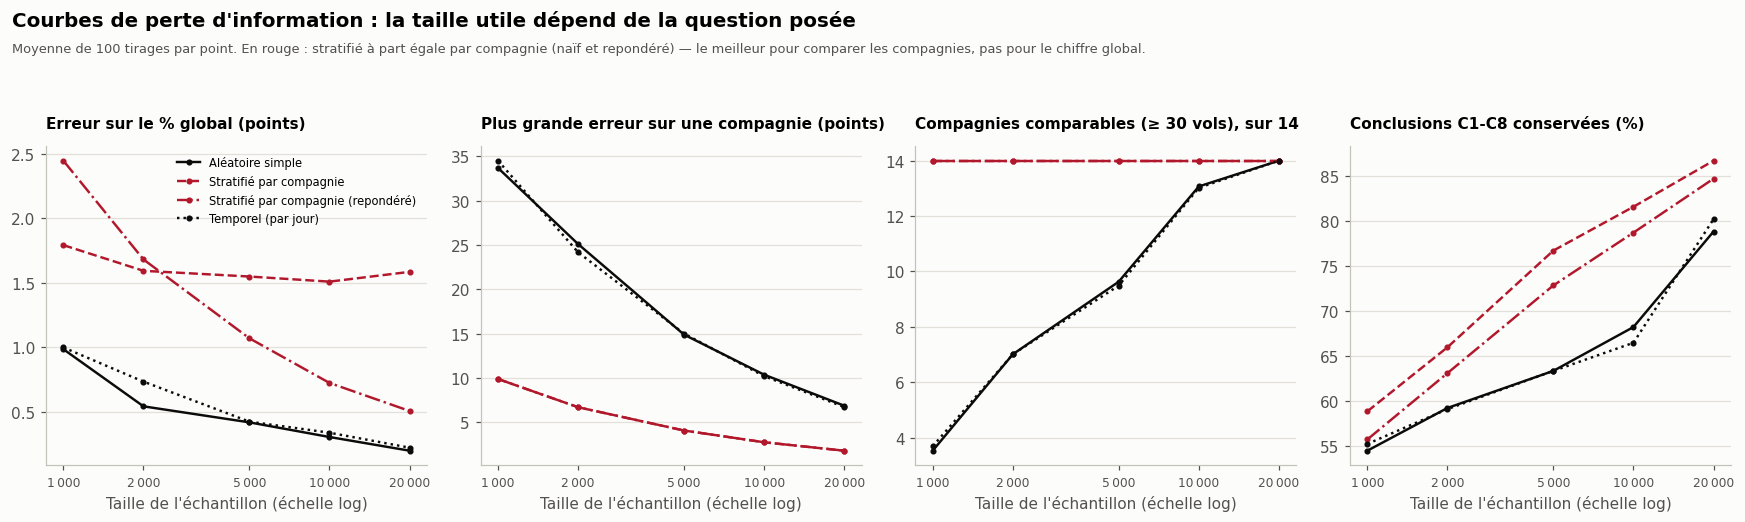

In [60]:
figures.s3_tailles(mesures_tailles); plt.show()

**Taille minimale pour qu'une conclusion reste vraie dans au moins 95 % des tirages :**

| Méthode | C1 | C2 | C3 | C4 | C5 | C6 | C7 | C8 |
|---|---|---|---|---|---|---|---|---|
| Aléatoire simple | 1 000 | 1 000 | > 20 000 | > 20 000 | > 20 000 | 2 000 | > 20 000 | 1 000 |
| Stratifié par compagnie | 5 000 | 1 000 | 10 000 | > 20 000 | > 20 000 | 1 000 | 20 000 | 1 000 |
| Stratifié par compagnie (repondéré) | 2 000 | 1 000 | 10 000 | > 20 000 | > 20 000 | 10 000 | > 20 000 | 1 000 |
| Temporel (par jour) | 1 000 | 1 000 | > 20 000 | > 20 000 | > 20 000 | 2 000 | > 20 000 | 1 000 |

> **Réponse.** Dans la version 1, la taille 5 000 n'était pas justifiée ; elle l'est maintenant par le calcul (section 5.8 :
> ± 1,07 point sur le % global) et par cette simulation. Le tableau se lit ainsi : avec un tirage aléatoire,
> 1 000 vols suffisent pour C1 (types de compagnies) et
> 2 000 pour C6 (effet domino) ; C3 demande un stratifié à part égale et
> 10 000 vols ; C4 et C5 ne sont robustes à aucune taille testée.
> Les courbes montrent qu'il n'y a pas de taille « bonne » dans l'absolu : l'erreur sur un chiffre global diminue vite
> (moins d'un point dès quelques milliers de vols),
> alors que comparer **toutes** les compagnies demande une stratification et plus de vols, et que certaines conclusions fines
> demandent plus de 20 000 vols. **5 000 vols est un compromis raisonnable pour les grandes conclusions**, à condition de
> choisir la méthode selon l'objectif.

## 10. Synthèse : ce qui est solide, ce qui est une piste, ce qui est un artefact

| Constat | Statut | Pourquoi | Suite |
|---|---|---|---|
| Les compagnies à bas coût sont plus souvent et plus gravement en retard que les régionales (30,6 % contre 12,1 %) | **Solide** | Grand écart, marges d'erreur séparées, vrai dans au moins 95 % des échantillons de 5 000 vols, quelle que soit la méthode | — |
| Le retard s'accumule au fil de la journée ; l'effet domino (15,4 % → 40,5 %) | **Solide** | Vrai pour toutes les compagnies mesurables, vrai dans au moins 92 % des échantillons | Causes : fichiers bruts BTS |
| Une partie des écarts vient de la composition (American et l'heure, SkyWest et le mois) | **Solide** pour ces compagnies | Standardisation directe | Autres facteurs (destinations) |
| Le classement du milieu change selon la saison | **Piste** | Une seule année | Comparer avec d'autres années |
| American « plus ponctuelle » que Delta | **Artefact** de composition et d'indicateur | S'inverse à heure égale et en comptant les annulations ; écarts dans la marge d'erreur | Ne pas conclure |
| Relation roulage-retard masquée par le mélange des compagnies | **Piste** (signal de type Simpson) | Corrélations faibles, mais positives dans 13 compagnies sur 14 | Analyse par compagnie |
| Le retard arrive par épisodes (10 événements réels : Spirit, Southwest, Omicron, tempêtes...) | **Solide** | Visibles dans nos données ET documentés par des sources | Causes officielles (BTS) |
| L'avantage des régionales est surtout celui d'Endeavor | **Solide** | Sans Endeavor : régionales 17,8 % contre majeures 19,7 % | — |
| Le milieu du classement (Delta, American, Envoy, Comair, United, SkyWest) | **Non départageable** | 28 paires sur 91 non distinctes (Bonferroni) | Ne pas classer au rang près |
| Mardi et mercredi plus calmes, vendredi plus difficile | **Solide mais faible** | Vrai à chaque saison ; V = 0,06 | — |
| À conditions égales, l'heure pèse plus que la compagnie | **Solide** | Modèle sur 314 844 vols ; intervalles de confiance serrés | — |
| La pluie et le vent augmentent le retard | **Solide** | Fusion météo, ρ = 0,43 sur 365 jours | Météo des destinations |
| New York et la Floride plus en retard | **Piste** | Non standardisé par compagnie et heure | Modèle avec la destination |

## 11. Limites et biais

- **Observationnel** : associations, pas causes ; les causes officielles ne sont pas dans le fichier utilisé.
- **Périmètre** : Atlanta, départs seulement ; Delta = 64,3 % des vols.
- **Une seule année** ; 2021-2022 est une période de reprise après le COVID.
- **Indicateurs** : seuil de 15 min (convention) ; biais du survivant corrigé par « retardé ou annulé ».
- **Compagnie opérante ou commerciale** : Endeavor vole pour Delta ; Republic et SkyWest pour plusieurs marques.
- **Effet domino** : mesuré sur les départs d'Atlanta seulement ; le rang du départ d'Atlanta ne mesure pas la position de l'avion dans sa journée.
- **Contexte réel** : les explications des épisodes viennent de sources extérieures (presse, compagnies) ; deux jours sans source de presse sont expliqués par la météo.
- **Tests** : avec 300 000 vols, tout est « significatif » ; on juge la **force** des liens (tous faibles, moins de 0,2).

## 11 bis. Journal des décisions (ce qui a été remis en question, et pourquoi)

| Décision | Ce qui l'a déclenchée | Ce qui a changé |
|---|---|---|
| Été 2022 → 12 mois | L'été surestime le retard (26 % contre 19 %) | Comparer les compagnies sur toutes les saisons |
| 8 → 6 méthodes d'échantillonnage | Garder les plans classiques | Mêmes conclusions, étude plus lisible |
| Courbe par mois → par jour | Revue critique | Les crises courtes apparaissent, reliées au monde réel |
| « American meilleure que Delta » | Inversion avec les annulations et à heure égale | Classé artefact |
| Classement au rang près | Test des 91 paires | Le milieu du classement est déclaré non départageable |
| « Les régionales sont les plus ponctuelles » | Version sans Endeavor | Nuancé : c'est surtout Endeavor |
| Le domino contredit par le rang ? | Rang 1 ≈ rang 3 | Limite des données expliquée ; domino vérifié à chaque heure |
| Fichiers → base SQL avec vues | Consigne : fusion et tables virtuelles | 5 tables fusionnées, 11 vues stockées et testées |
| Presse seule → presse + météo | Deux jours sans source | Expliqués par la pluie et le vent |
| Analyses une à une → modèle | Les facteurs se mélangent | L'heure pèse plus que la compagnie |
| Nom « Comair » | Recherche sur le code OH | Nom périmé (PSA Airlines) signalé |

## 12. Conclusion

Les compagnies se distinguent surtout par leur **modèle** : les régionales (Endeavor en tête sur l'année) sont les plus ponctuelles,
les compagnies à bas coût les moins ponctuelles, avec des retards plus graves. Une partie des écarts restants tient à la
**composition** de leurs vols (heure, mois). Ces grandes conclusions résistent à toutes les méthodes d'échantillonnage ;
les écarts fins entre compagnies proches, non. **Le bon échantillon dépend de la question** : stratifier par compagnie
pour comparer les compagnies, tirer au hasard pour un chiffre global, éviter les grappes de jours.

Vu **jour par jour**, le retard arrive surtout par **épisodes** : des crises courtes, souvent propres à une compagnie (Spirit en août 2021, Southwest en octobre, JetBlue en janvier) ou à tout l'aéroport (Noël 2021, tempête du 16 janvier), que nous avons reliées à des événements réels documentés. Le milieu du classement n'est pas départageable ; l'avantage des régionales est surtout celui d'Endeavor.

Enfin, **à conditions égales** (modèle), l'heure de départ pèse plus que la compagnie, et la météo d'Atlanta (fusion) explique une
partie des mauvais jours : du meilleur au pire vol possible, le risque de retard va de 1,6 % à 81,5 %.